# Домашнее задание по теме «Логистическая регрессия и SVM»

В домашней работе ты реализуешь логистическую регрессию, сравнишь преобразования целевой переменной и проверишь калибровку вероятностей.

**Максимальная оценка: 10 баллов.** Задания 1–8 дают соответственно 2, 1,5, 0,5, 1,5, 0,5, 2, 1 и 1 балл. Баллы подзадач входят в оценку задания и не суммируются с ней повторно. Задания со звёздочкой входят в этот максимум.

## Логистическая регрессия

Реализуй бинарную логистическую регрессию без регуляризации. Вычисляй градиенты сразу по всей выборке, без циклов по объектам. Цикл по итерациям градиентного спуска нужен. Затем проверь модель на Wine и построй границы для пар признаков. Проверки ниже охватывают основные свойства реализации, но не доказывают корректность на любых данных.

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_wine, load_breast_cancer
from sklearn.model_selection import train_test_split

# Загружаем данные
data = load_wine()
X = data.data
y = data.target
# Оставляем только объекты классов 0 и 1
mask = y < 2
X = X[mask]
y = y[mask]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)
feature_names = data.feature_names
# Масштабирование обучаем только на train.
X_train_raw, X_test_raw = X_train.copy(), X_test.copy()
scaler = StandardScaler().fit(X_train_raw)
X_train = scaler.transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

### Задание 1 [2 балла]

Напиши класс `LogisticRegression`. Используй среднюю бинарную кросс-энтропию и полный градиент по train. В `fit` заново инициализируй веса, очисти `losses` и сохраняй потерю после каждой итерации. Метод возвращает `self`. Для устойчивого вычисления потерь по логитам используй `np.logaddexp(0, z) - y*z`.

In [40]:
class LogisticRegression:
    def __init__(self, lr=0.01, iterations=1000):
        self.lr = lr
        self.iterations = iterations
        self.w = None
        self.b = None
        self.losses = []

    def initialize_parameters(self, X):
        """
        Инициализирует веса и смещение нулями
        Принимает:
            X (ndarray, shape: [n_samples, n_features]): обучающие признаки
        На выходе:
            ничего не возвращает
        """
        # Напиши код здесь
        self.w = np.zeros(X.shape[1])
        self.b = 0.0

    def _sigmoid(self, z):
        """
        Вычисляет сигмоидную функцию активации: 1 / (1 + e^(-z))
        Принимает:
            z (ndarray): входные значения
        Возвращает:
            sigmoid (ndarray): значения после сигмоиды
        """
        z = np.clip(z, -500, 500)  # Ограничиваем значения, чтобы избежать переполнения
        # Напиши код здесь
        sigmoid = 1 / (1 + np.exp(-z))
        return sigmoid

    def compute_loss(self, X, y):
        """
        Вычисляет функцию потерь: бинарная кросс-энтропия
            L = -1/n * Σ(y*log(p) + (1-y)*log(1-p))
            Подсказка: используй np.mean(np.logaddexp(0, z) - y*z)
        Принимает:
            X (ndarray): массив признаков
            y (ndarray): вектор меток классов (0 или 1)
        Возвращает:
            loss (float): значение функции потерь
        """
        # Напиши код здесь
        z = X @ self.w + self.b
        loss = np.mean(np.logaddexp(0, z) - y * z)
        return loss

    def step(self, X, y):
        """
        Один шаг градиентного спуска по всей выборке

        Принимает:
            X (ndarray, shape: [n_samples, n_features]): обучающие признаки
            y (ndarray): метки классов (0 или 1)

        Возвращает:
            ничего не возвращает, обновляет веса и смещение
        """
        # Напиши код здесь
        n = X.shape[0]
        
        z = X @ self.w + self.b
        p = self._sigmoid(z)
        dw = X.T @ (p - y) / n
        db = np.mean(p - y)
        self.w -= self.lr * dw
        self.b -= self.lr * db


    def fit(self, X, y):
        """
        Обучает логистическую регрессию на тренировочных данных

        Принимает:
            X (ndarray, shape: [n_samples, n_features]): обучающие признаки
            y (ndarray): метки классов (0 или 1)

        Возвращает:
            self: обученный объект
        """
        # Напиши код здесь
        self.initialize_parameters(X)
        self.losses = []
        
        for _ in range(self.iterations):
            self.step(X, y)
            loss = self.compute_loss(X, y)
            self.losses.append(loss)

        return self

    def predict_proba(self, X):
        """
        Делает вероятностное предсказание

        Принимает:
            X (ndarray, shape: [n_samples, n_features]): обучающие признаки

        Возвращает:
            probs (ndarray): предсказанные вероятности классов
        """
        z = np.dot(X, self.w) + self.b
        probs = self._sigmoid(z)
        return np.vstack([1 - probs, probs]).T

    def predict(self, X):
        """
        Делает бинарное предсказание: класс 0 или 1

        Принимает:
            X (ndarray, shape: [n_samples, n_features]): обучающие признаки

        Возвращает:
            preds (ndarray): предсказанные метки классов
        """
        # Напиши код здесь
        probs = self.predict_proba(X)[:, 1]
        preds = (probs >= 0.5).astype(int)
        return preds

Проверь формы массивов, значения сигмоиды и работу основных методов. Для обучения далее используем масштабированные признаки.

In [41]:
import numpy as np

model = LogisticRegression()
model.initialize_parameters(X_train)

# Проверка initialize_parameters
assert model.w.shape == (X_train.shape[1],), "Ошибка: некорректная размерность весов w"
assert np.all(model.w == 0), "Ошибка: веса должны быть инициализированы нулями"
assert model.b == 0, "Ошибка: смещение должно быть инициализировано нулём"
print("Модуль initialize_parameters работает корректно")

# Проверка _sigmoid
z_test = np.array([0, 2])
sigmoid_vals = model._sigmoid(z_test)
assert np.allclose(sigmoid_vals, [0.5, 1 / (1 + np.exp(-2))]), "Ошибка: сигмоида рассчитывается некорректно"
print("Модуль _sigmoid работает корректно")

# Проверка compute_loss
loss = model.compute_loss(X_train, y_train)
assert isinstance(loss, float), "Ошибка: функция потерь должна возвращать число"
assert np.isclose(loss, np.log(2)), "При нулевых весах потеря должна равняться log(2)"
print("Модуль compute_loss работает корректно")

# Проверка step
old_w = model.w.copy()
old_b = model.b
model.step(X_train, y_train)

assert not np.allclose(model.w, old_w), "Ошибка: веса не изменились после шага градиентного спуска"
assert model.w.shape == old_w.shape, "Ошибка: форма весов изменилась после обновления"
assert model.b != old_b, "Ошибка: смещение не обновилось"
print("Модуль step работает корректно")

# Проверка fit
model.fit(X_train, y_train)
assert model.w is not None, "Ошибка: веса не определены после обучения"
assert model.b is not None, "Ошибка: смещение не определено после обучения"
print("Модуль fit работает корректно")

# Проверка predict
preds = model.predict(X_test)
assert preds.shape == y_test.shape, "Ошибка: размерность предсказаний не совпадает с y_test"
assert set(np.unique(preds)).issubset({0, 1}), "Ошибка: предсказания должны быть бинарными (0 или 1)"
print("Модуль predict работает корректно")

assert len(model.losses) == model.iterations
assert model.losses[-1] < model.losses[0]
assert np.allclose(model.predict_proba(X_test).sum(axis=1), 1)
model.fit(X_train, y_train)
assert len(model.losses) == model.iterations, "История должна сбрасываться при повторном fit"
print("Все тесты пройдены")

Модуль initialize_parameters работает корректно
Модуль _sigmoid работает корректно
Модуль compute_loss работает корректно
Модуль step работает корректно
Модуль fit работает корректно
Модуль predict работает корректно
Все тесты пройдены


In [42]:
# Проверим, что модель работает

model = LogisticRegression()
model.fit(X_train, y_train)
preds = model.predict(X_test)

print(preds)

[0 0 0 0 1 0 1 1 1 0 0 0 1 0 1 1 0 1 1 1 0 0 1 0 1 0 1 1 0 0 0 0 0 0 1 1 1
 0 1 0 0 1 1 0 1 1 0 0 0 1 1 0]


### Задание 2 [1,5 балла]

Построй границы для всех пар признаков Wine. Для каждой пары обучи `StandardScaler` на `X_train_raw[:, [i, j]]`, преобразуй train и обучи свою логистическую регрессию. Сетку создавай в исходных единицах и преобразуй тем же scaler перед `predict_proba`.

Используй `XX, YY = np.meshgrid(xx, yy)`, фон вероятностей со шкалой от 0 до 1 и линию уровня 0,5. На рисунке покажи объекты train. Разбей 78 пар на несколько рисунков, чтобы подписи оставались читаемыми. Это иллюстрация работы моделей на train, а не оценка качества на новых данных.

In [43]:
from itertools import combinations

def plot_logreg_boundaries_all_pairs(X_train_raw, y_train, feature_names, model_class):
    pairs = list(combinations(range(X_train_raw.shape[1]), 2))

    for start in range(0, len(pairs), 12):
        fig, axes = plt.subplots(
            3, 4,
            figsize=(22, 15),
            layout="constrained"
        )
        axes = axes.ravel()

        for ax, (i, j) in zip(axes, pairs[start:start + 12]):
            X_pair = X_train_raw[:, [i, j]]

            scaler = StandardScaler()
            X_scaled = scaler.fit_transform(X_pair)

            model = model_class(lr=0.1, iterations=1000)
            model.fit(X_scaled, y_train)

            x_min, x_max = X_pair[:, 0].min() - 0.5, X_pair[:, 0].max() + 0.5
            y_min, y_max = X_pair[:, 1].min() - 0.5, X_pair[:, 1].max() + 0.5

            xx = np.linspace(x_min, x_max, 100)
            yy = np.linspace(y_min, y_max, 100)

            XX, YY = np.meshgrid(xx, yy)

            grid = np.c_[XX.ravel(), YY.ravel()]
            grid_scaled = scaler.transform(grid)

            Z = model.predict_proba(grid_scaled)[:, 1]
            Z = Z.reshape(XX.shape)

            contour = ax.contourf(
                XX, YY, Z,
                levels=np.linspace(0, 1, 21),
                cmap="RdBu_r",
                vmin=0,
                vmax=1
            )

            ax.contour(
                XX, YY, Z,
                levels=[0.5],
                colors="black",
                linewidths=1.5
            )

            ax.scatter(
                X_pair[:, 0],
                X_pair[:, 1],
                c=y_train,
                cmap="bwr",
                edgecolors="black",
                s=20
            )

            ax.set_xlabel(feature_names[i], fontsize=10)
            ax.set_ylabel(feature_names[j], fontsize=10)
            ax.tick_params(labelsize=9)

        for ax in axes[len(pairs[start:start + 12]):]:
            ax.axis("off")

        fig.colorbar(
            contour,
            ax=axes.tolist(),
            label="P(y=1)",
            shrink=0.7
        )

        fig.suptitle(
            f"Границы решений Wine — пары {start + 1}–{min(start + 12, len(pairs))}",
            fontsize=16
        )

        plt.show()

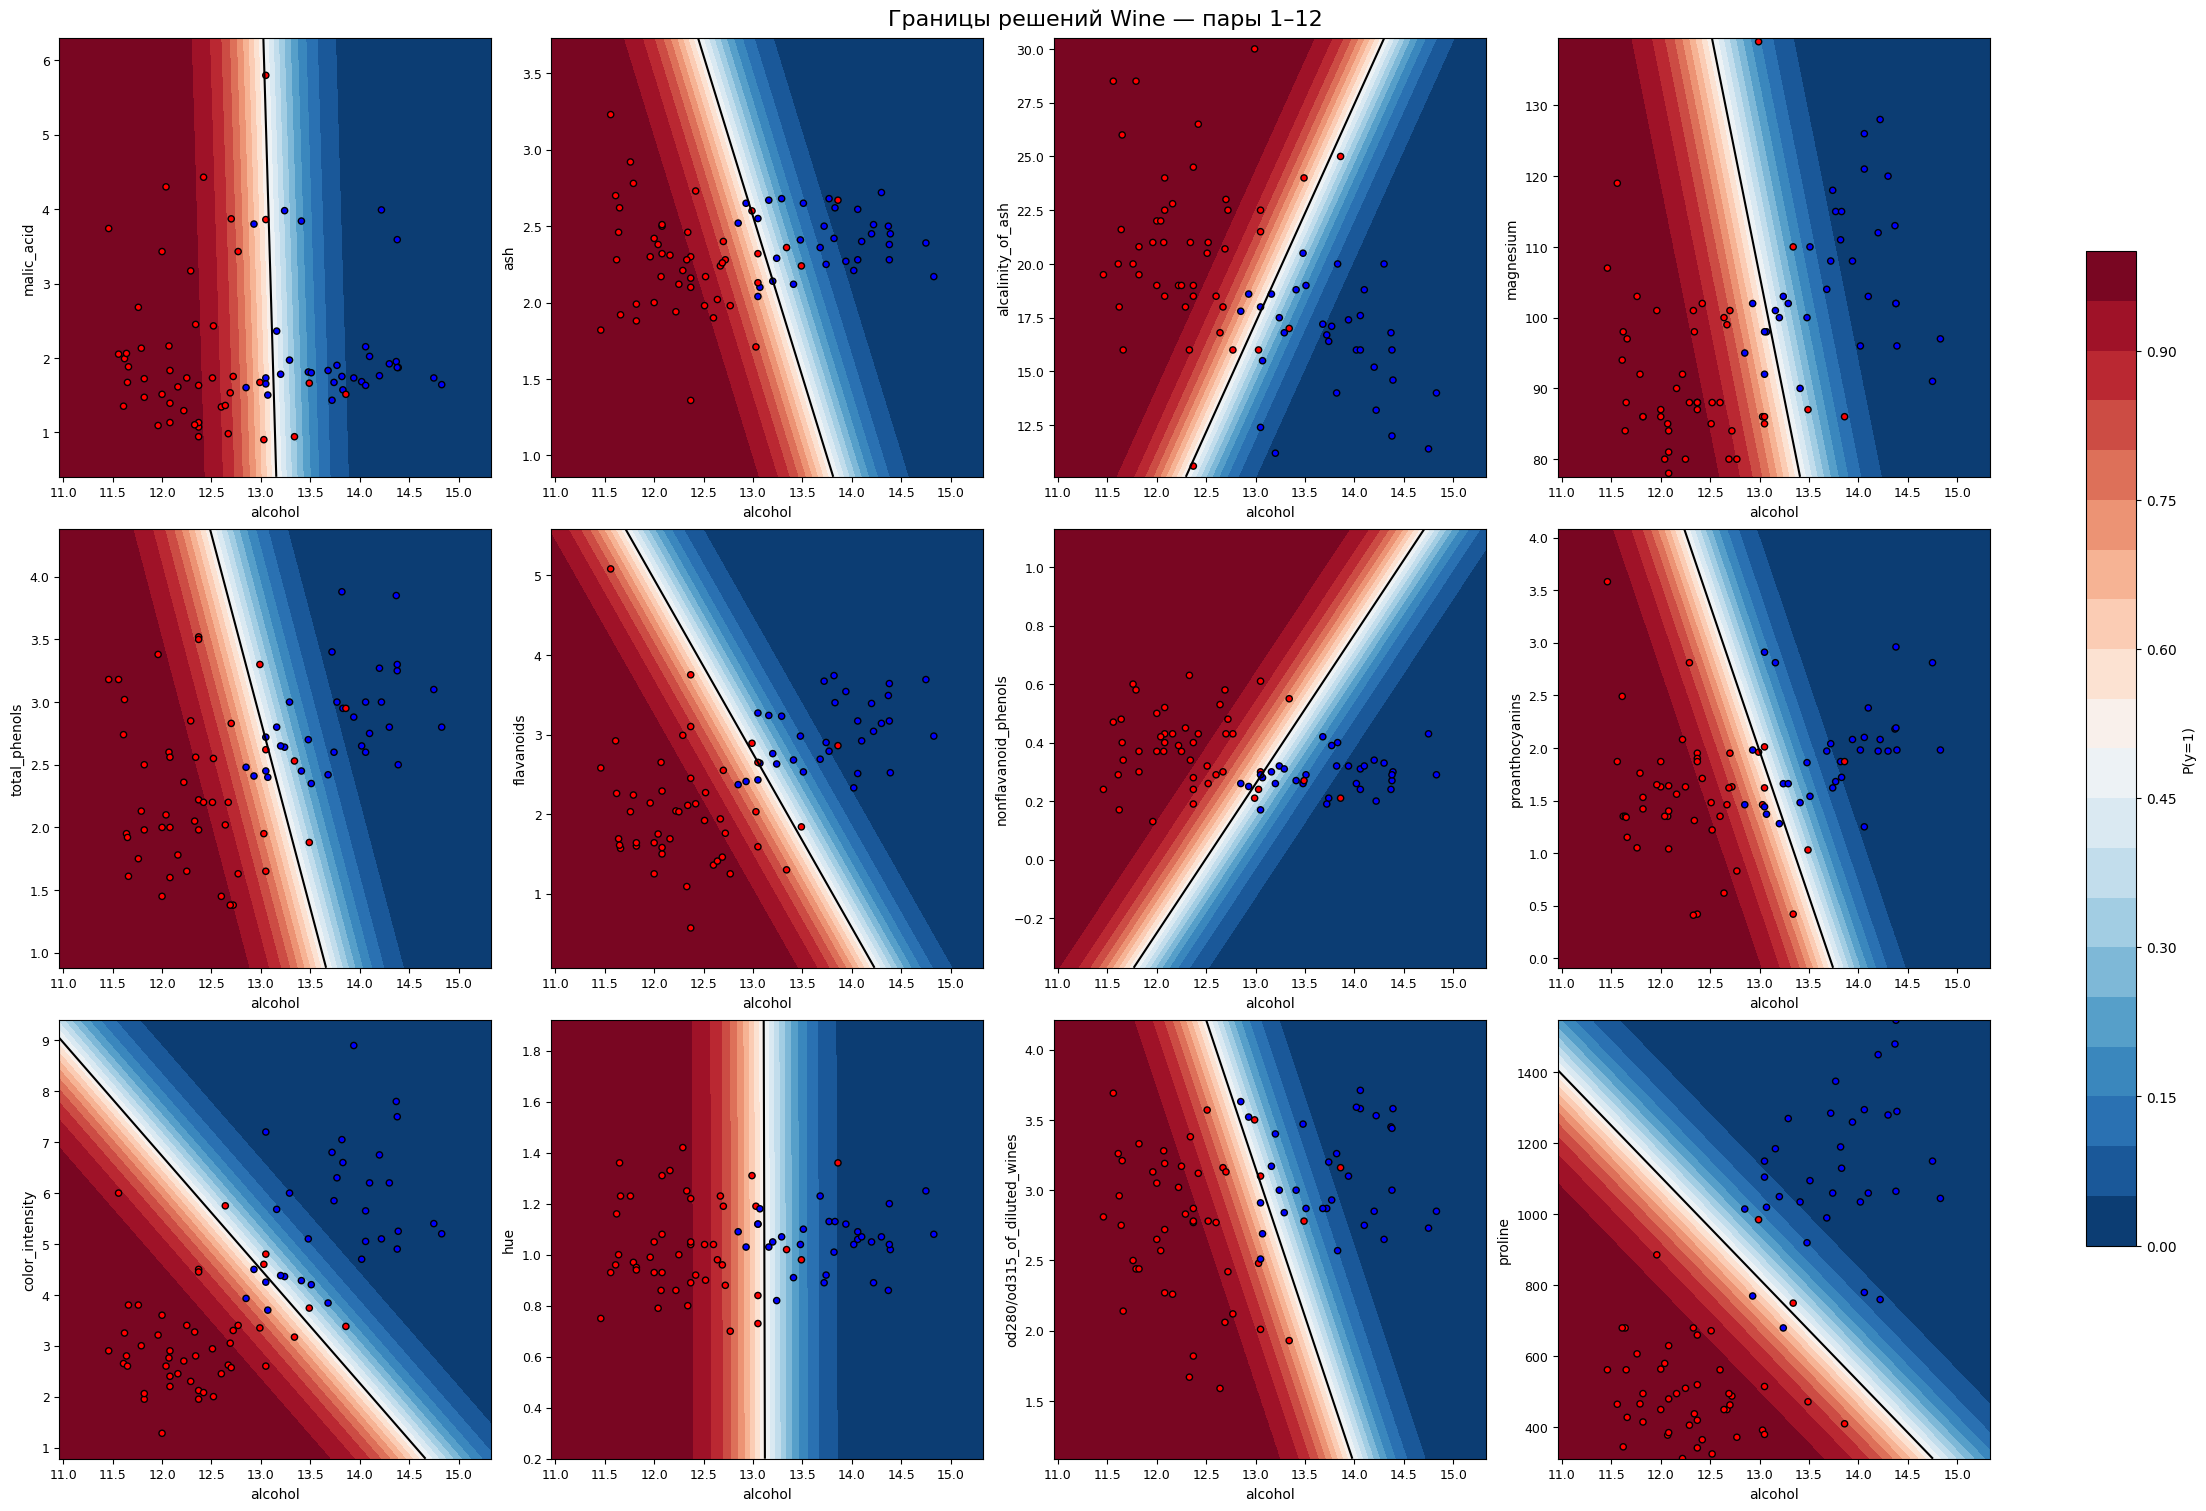

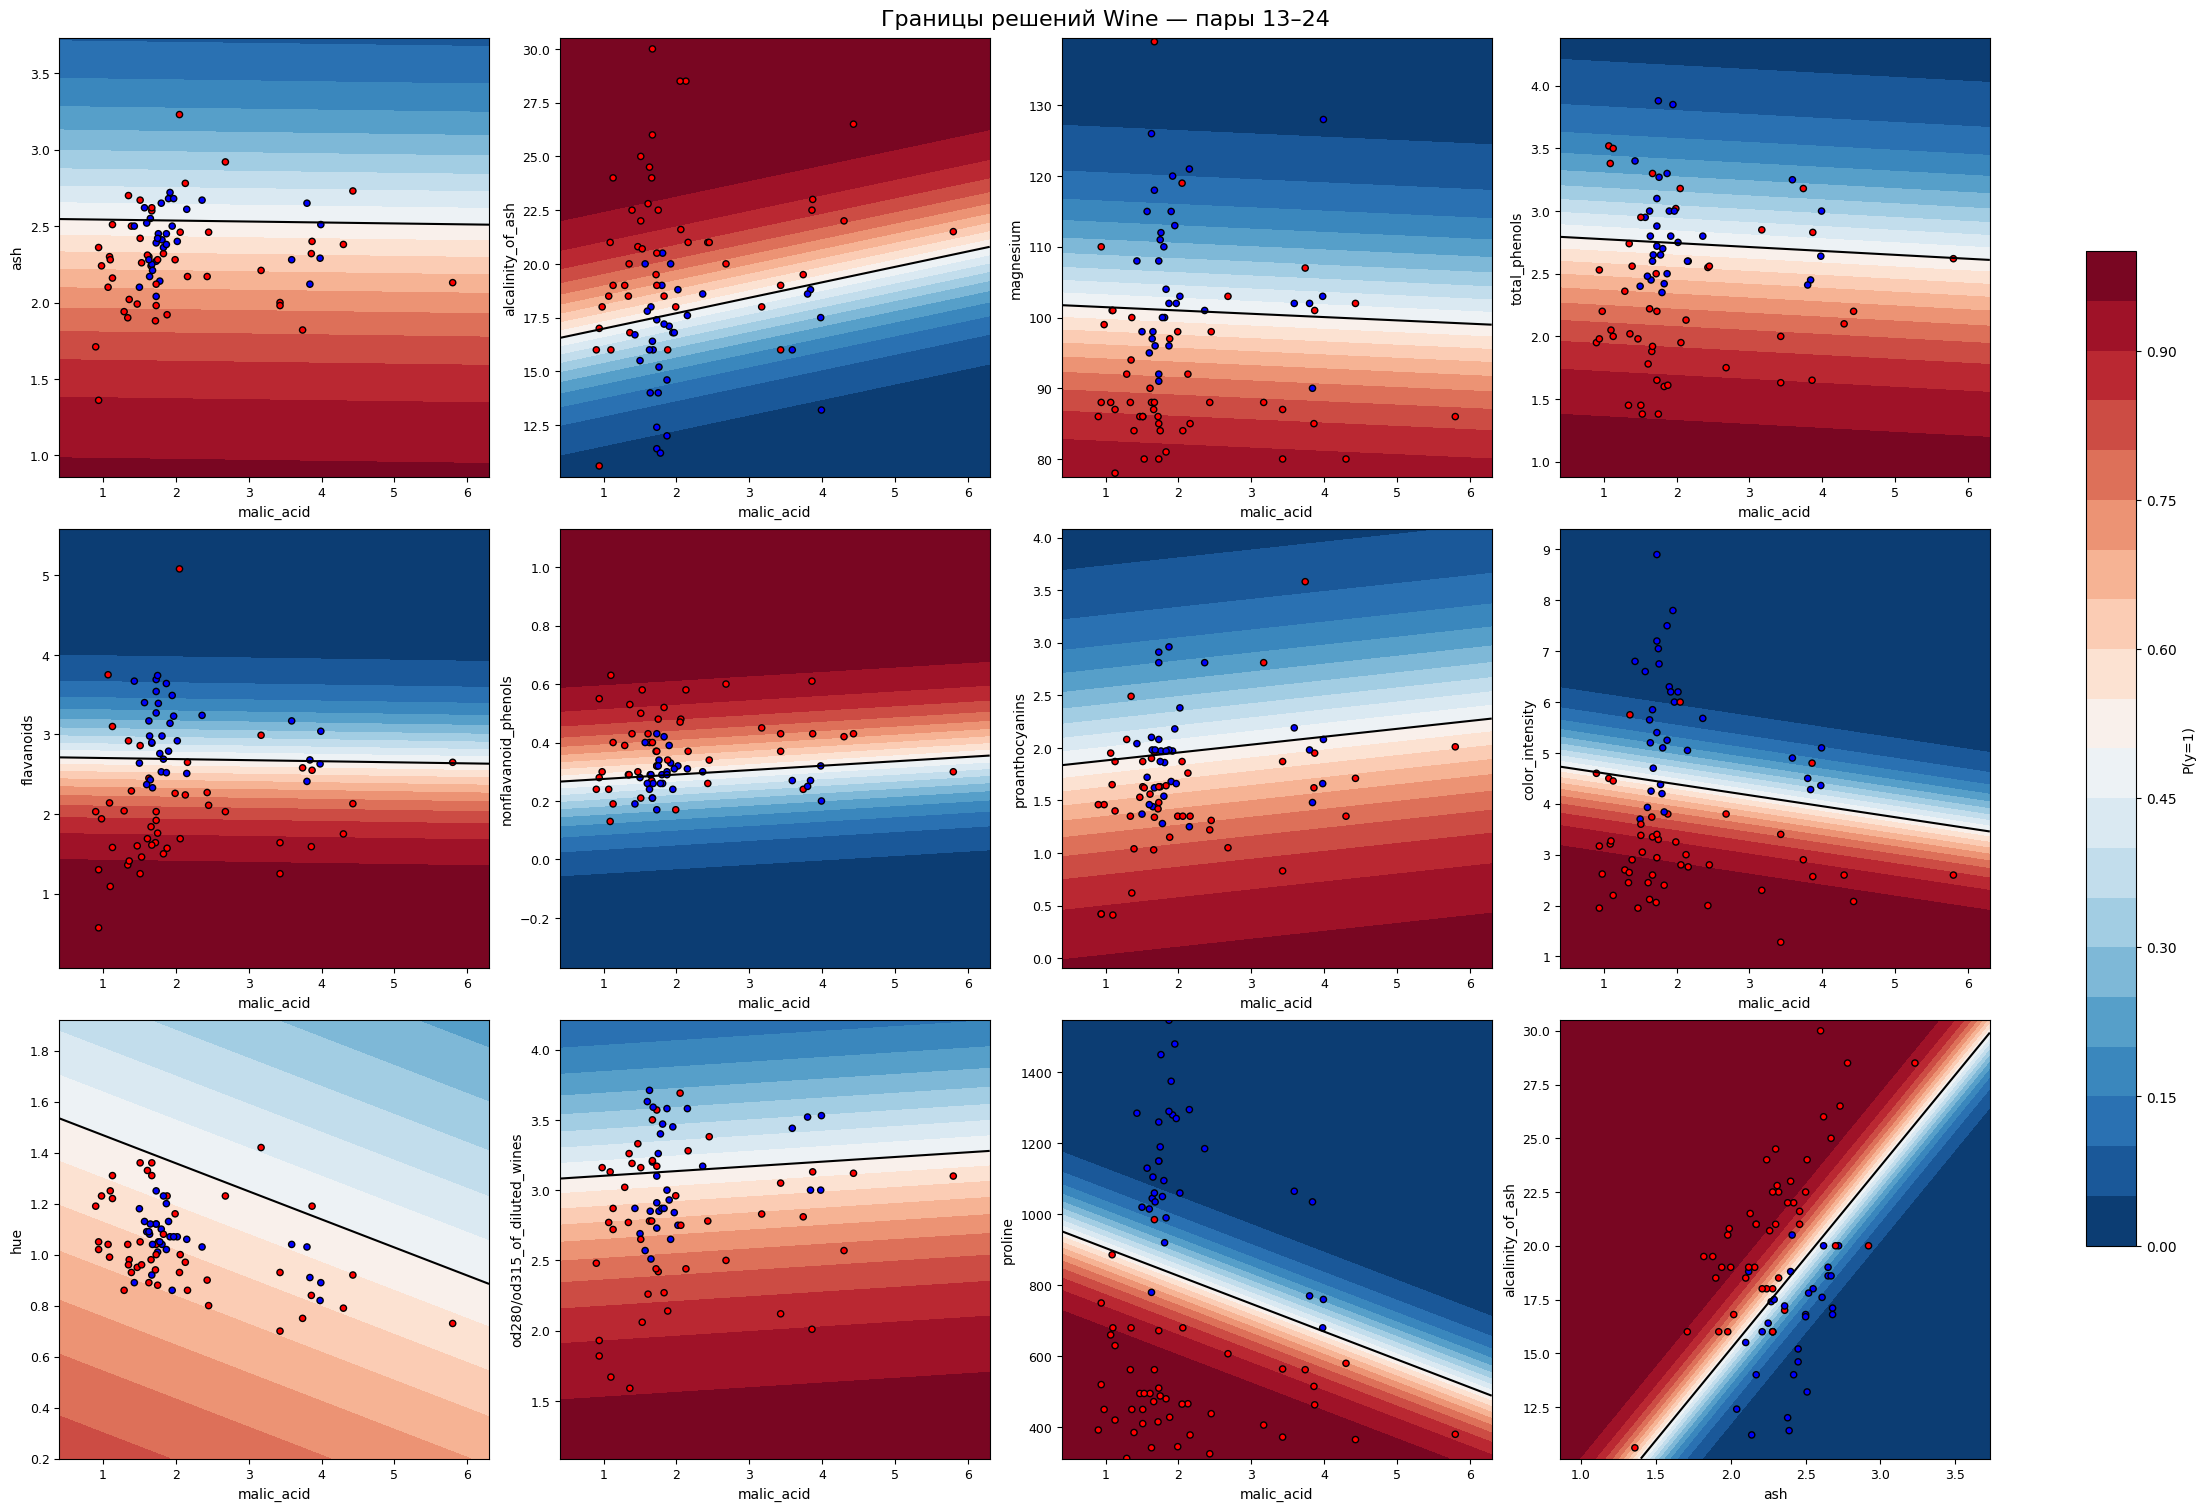

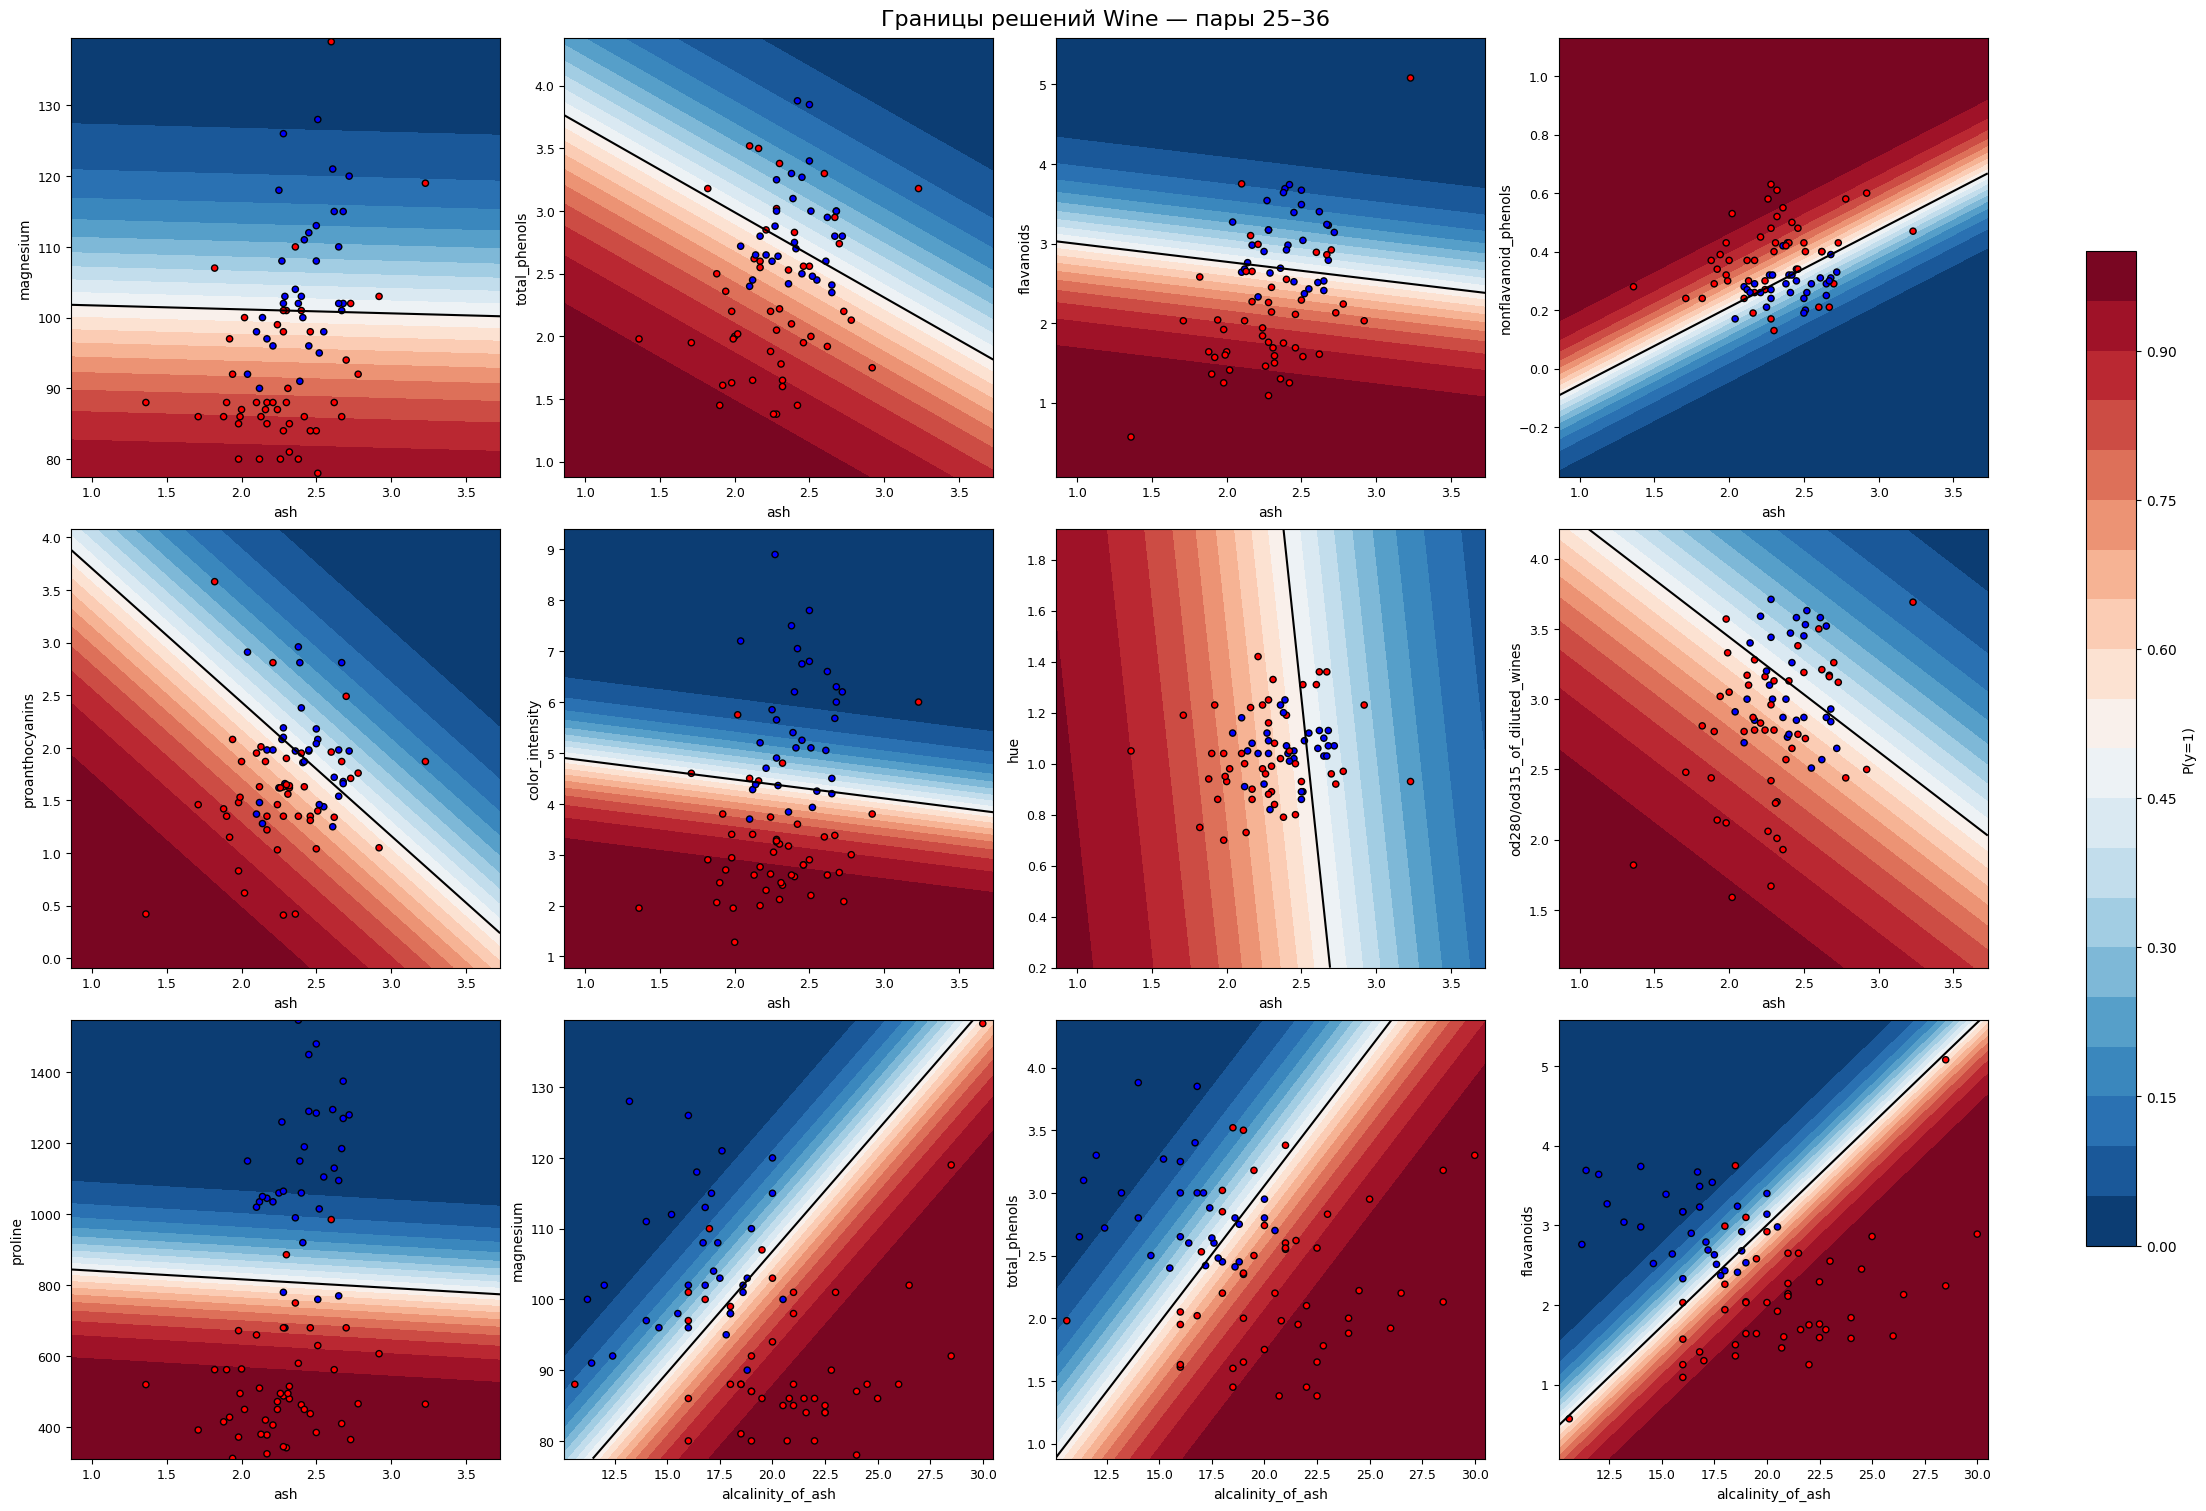

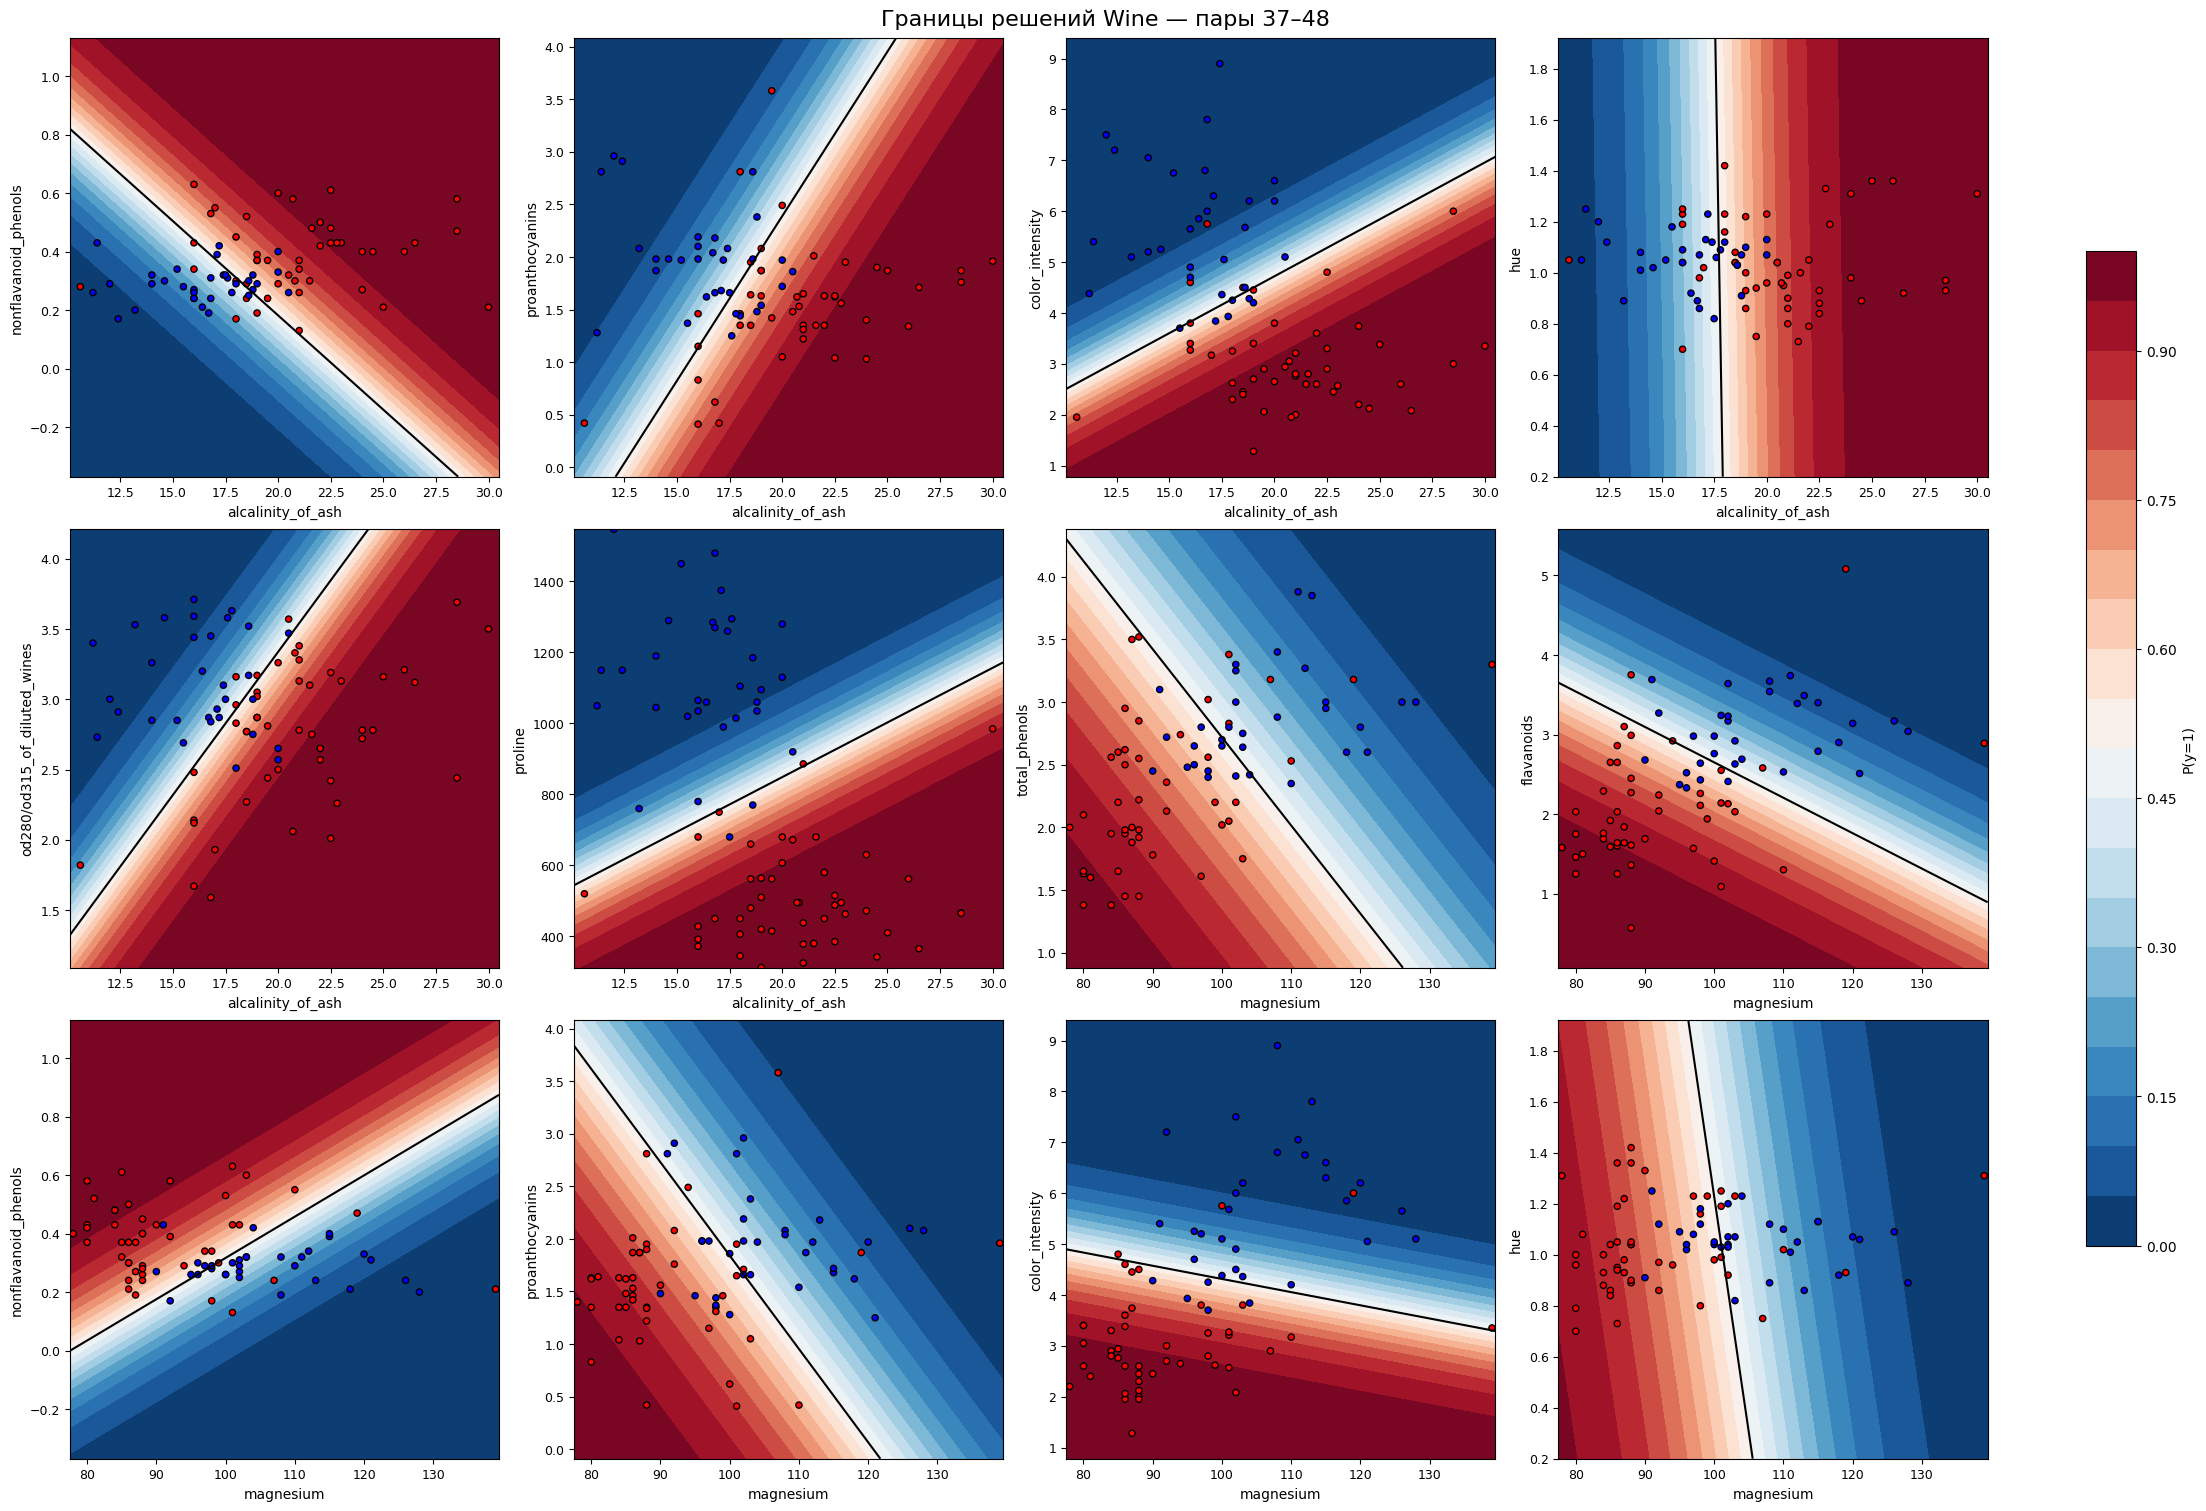

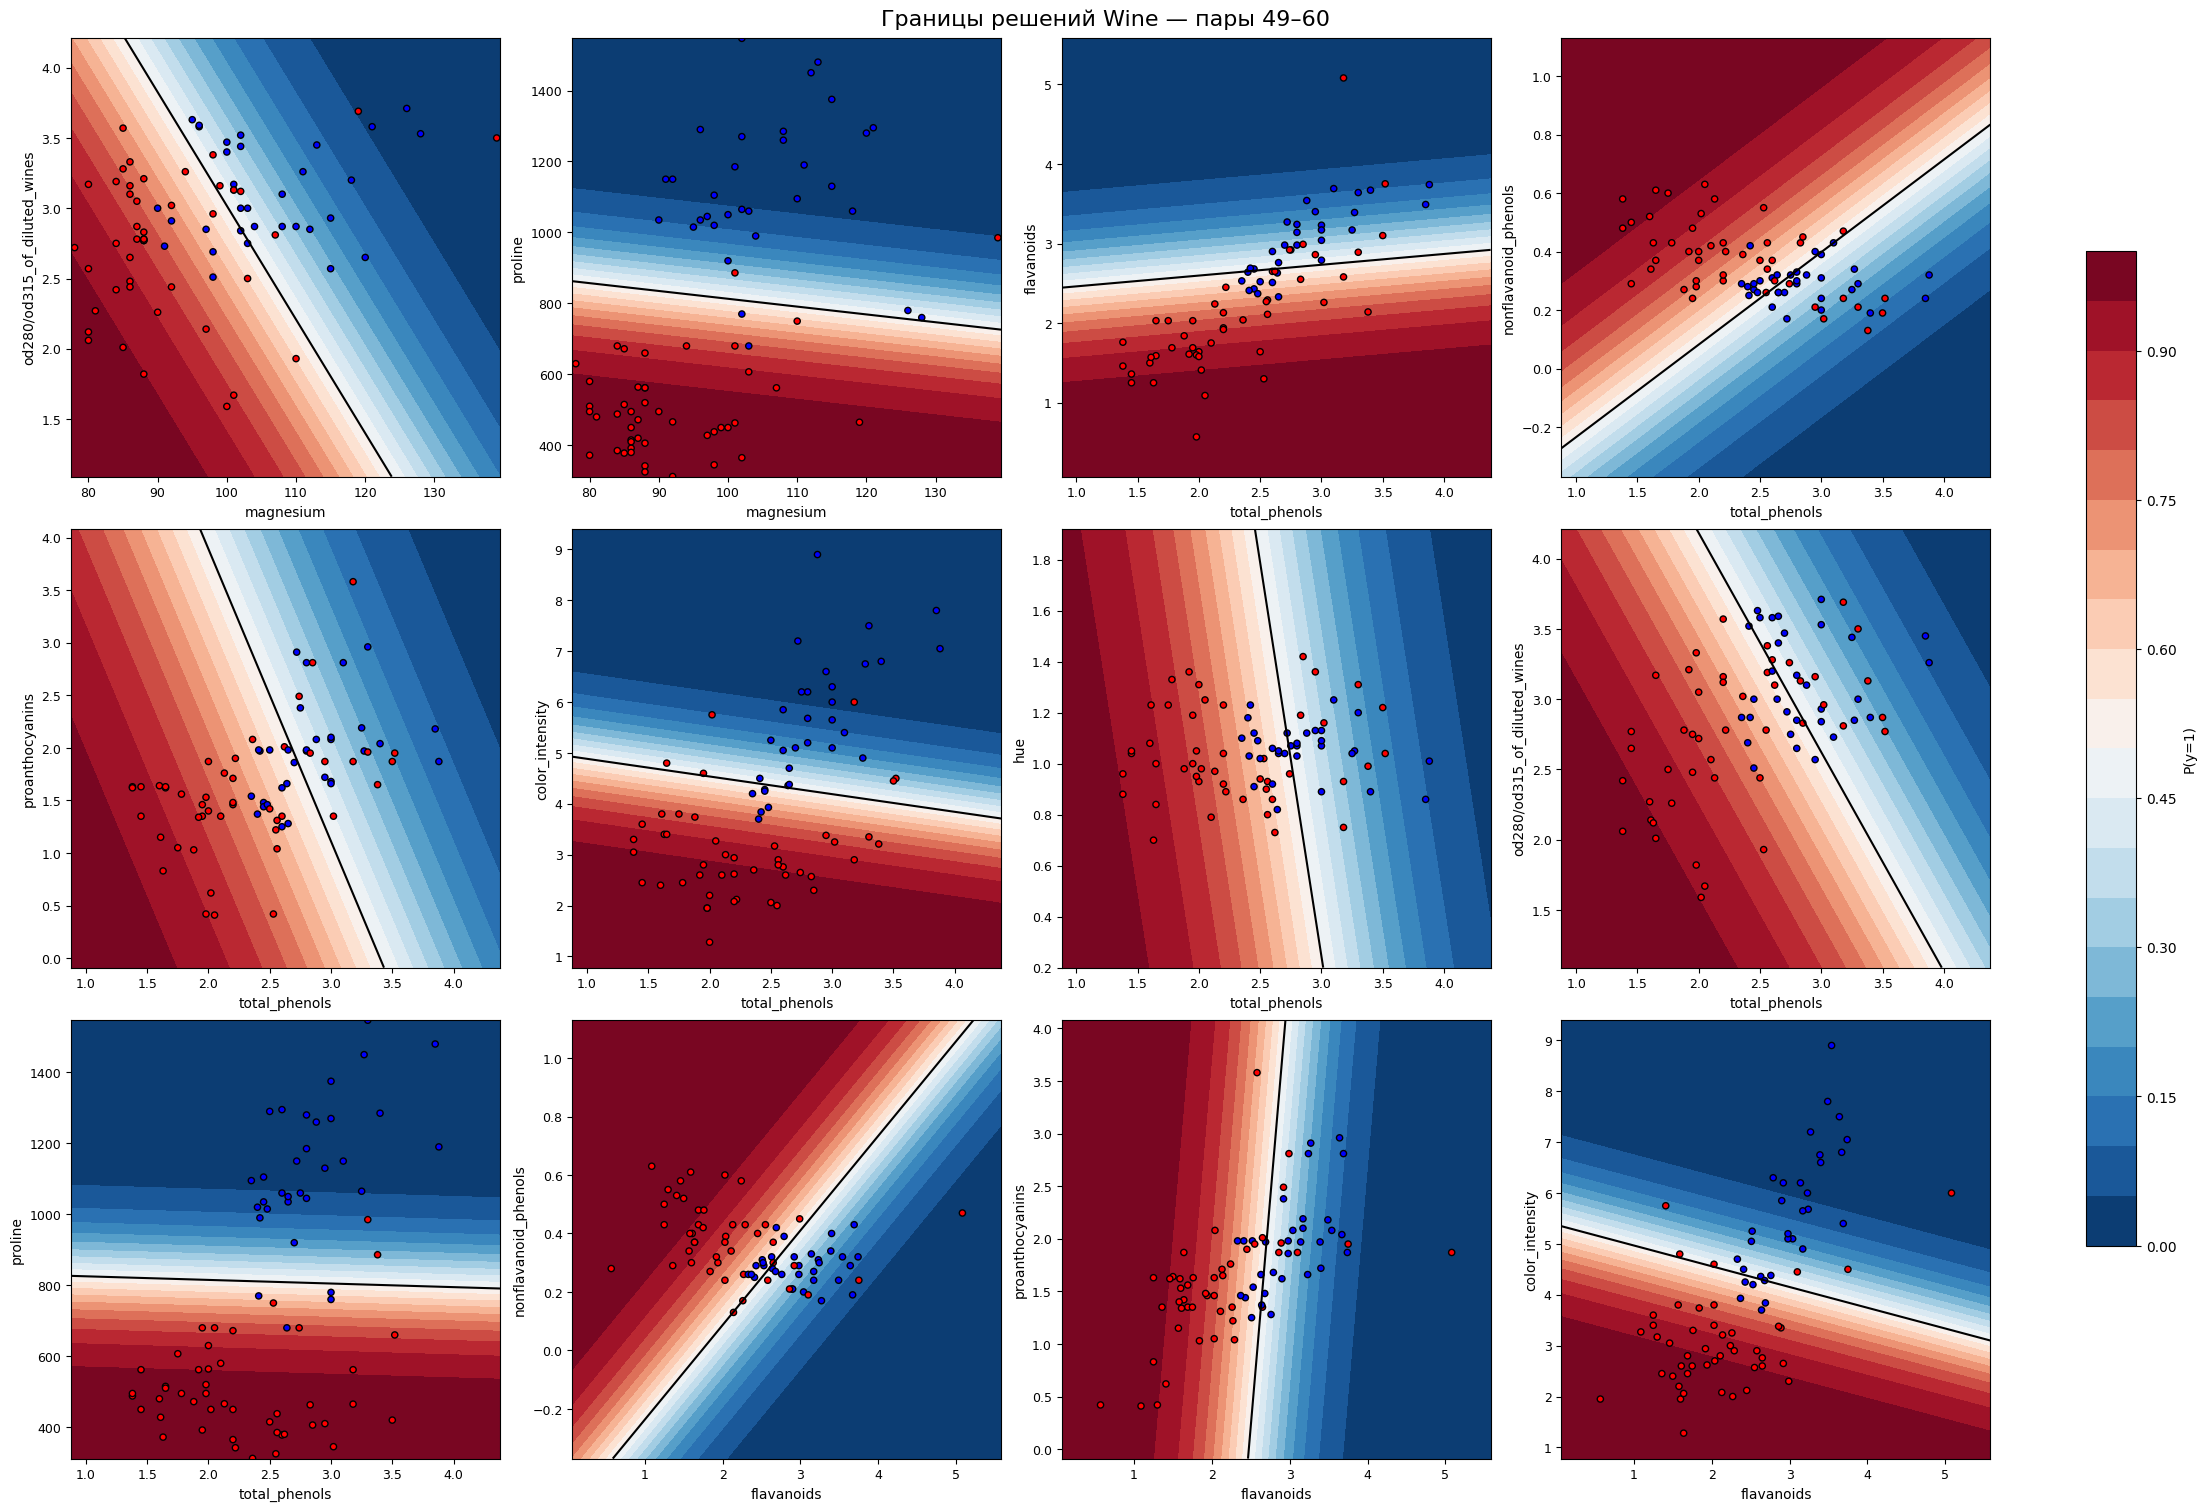

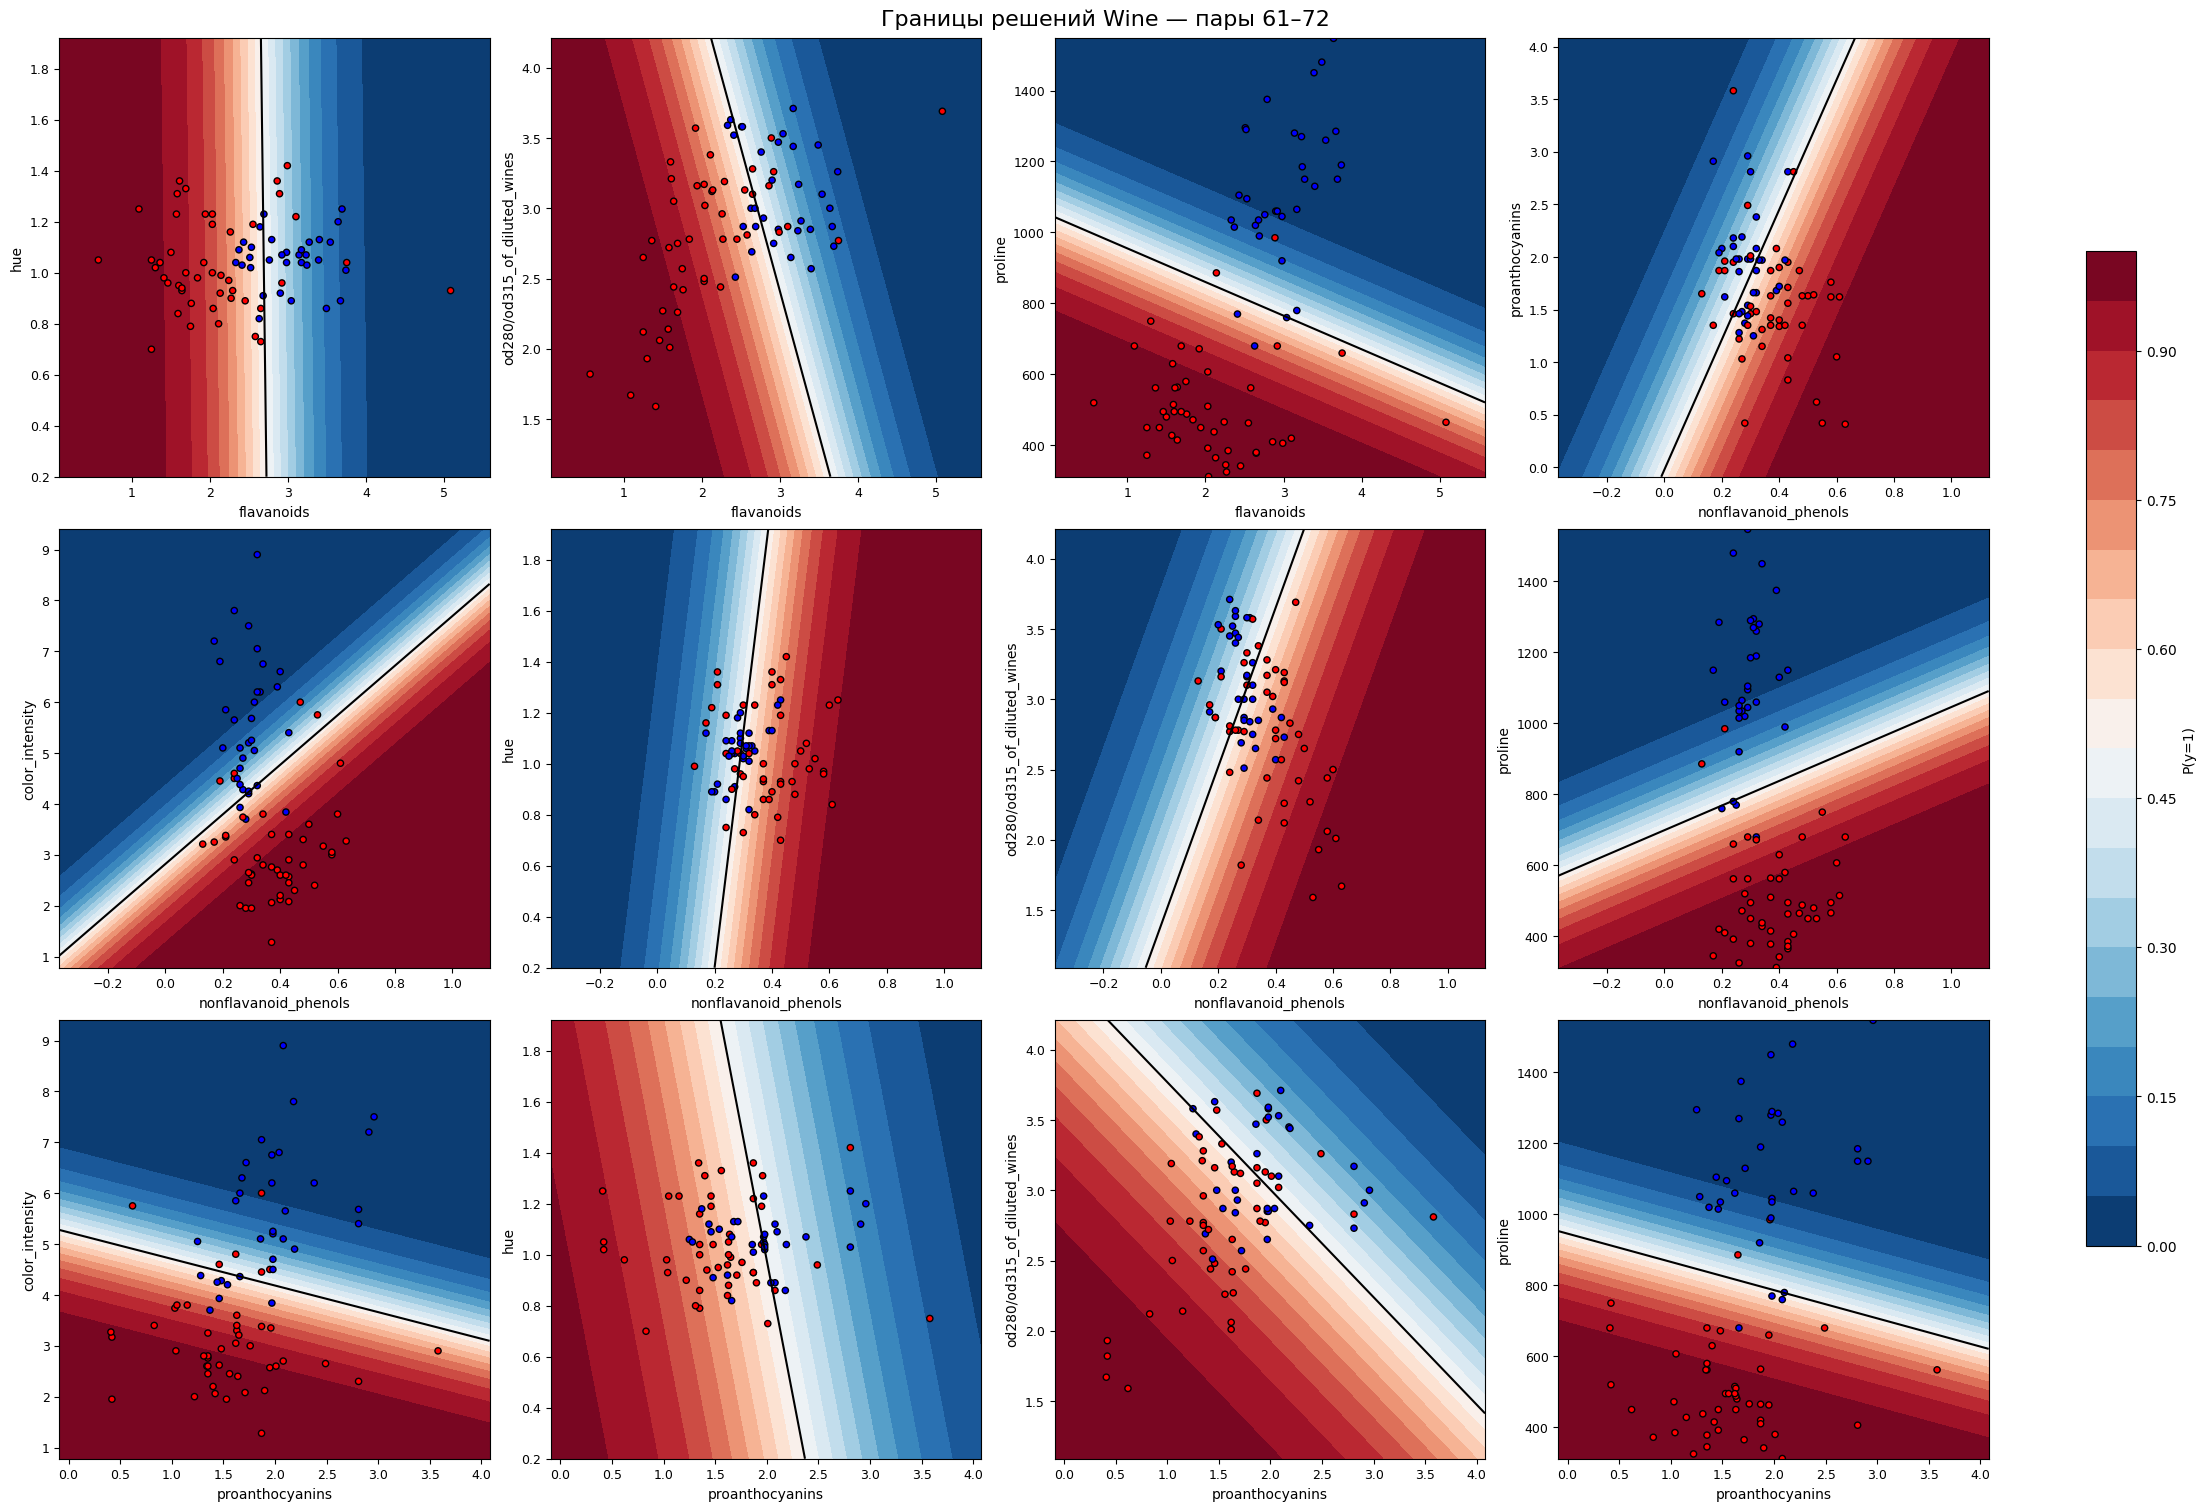

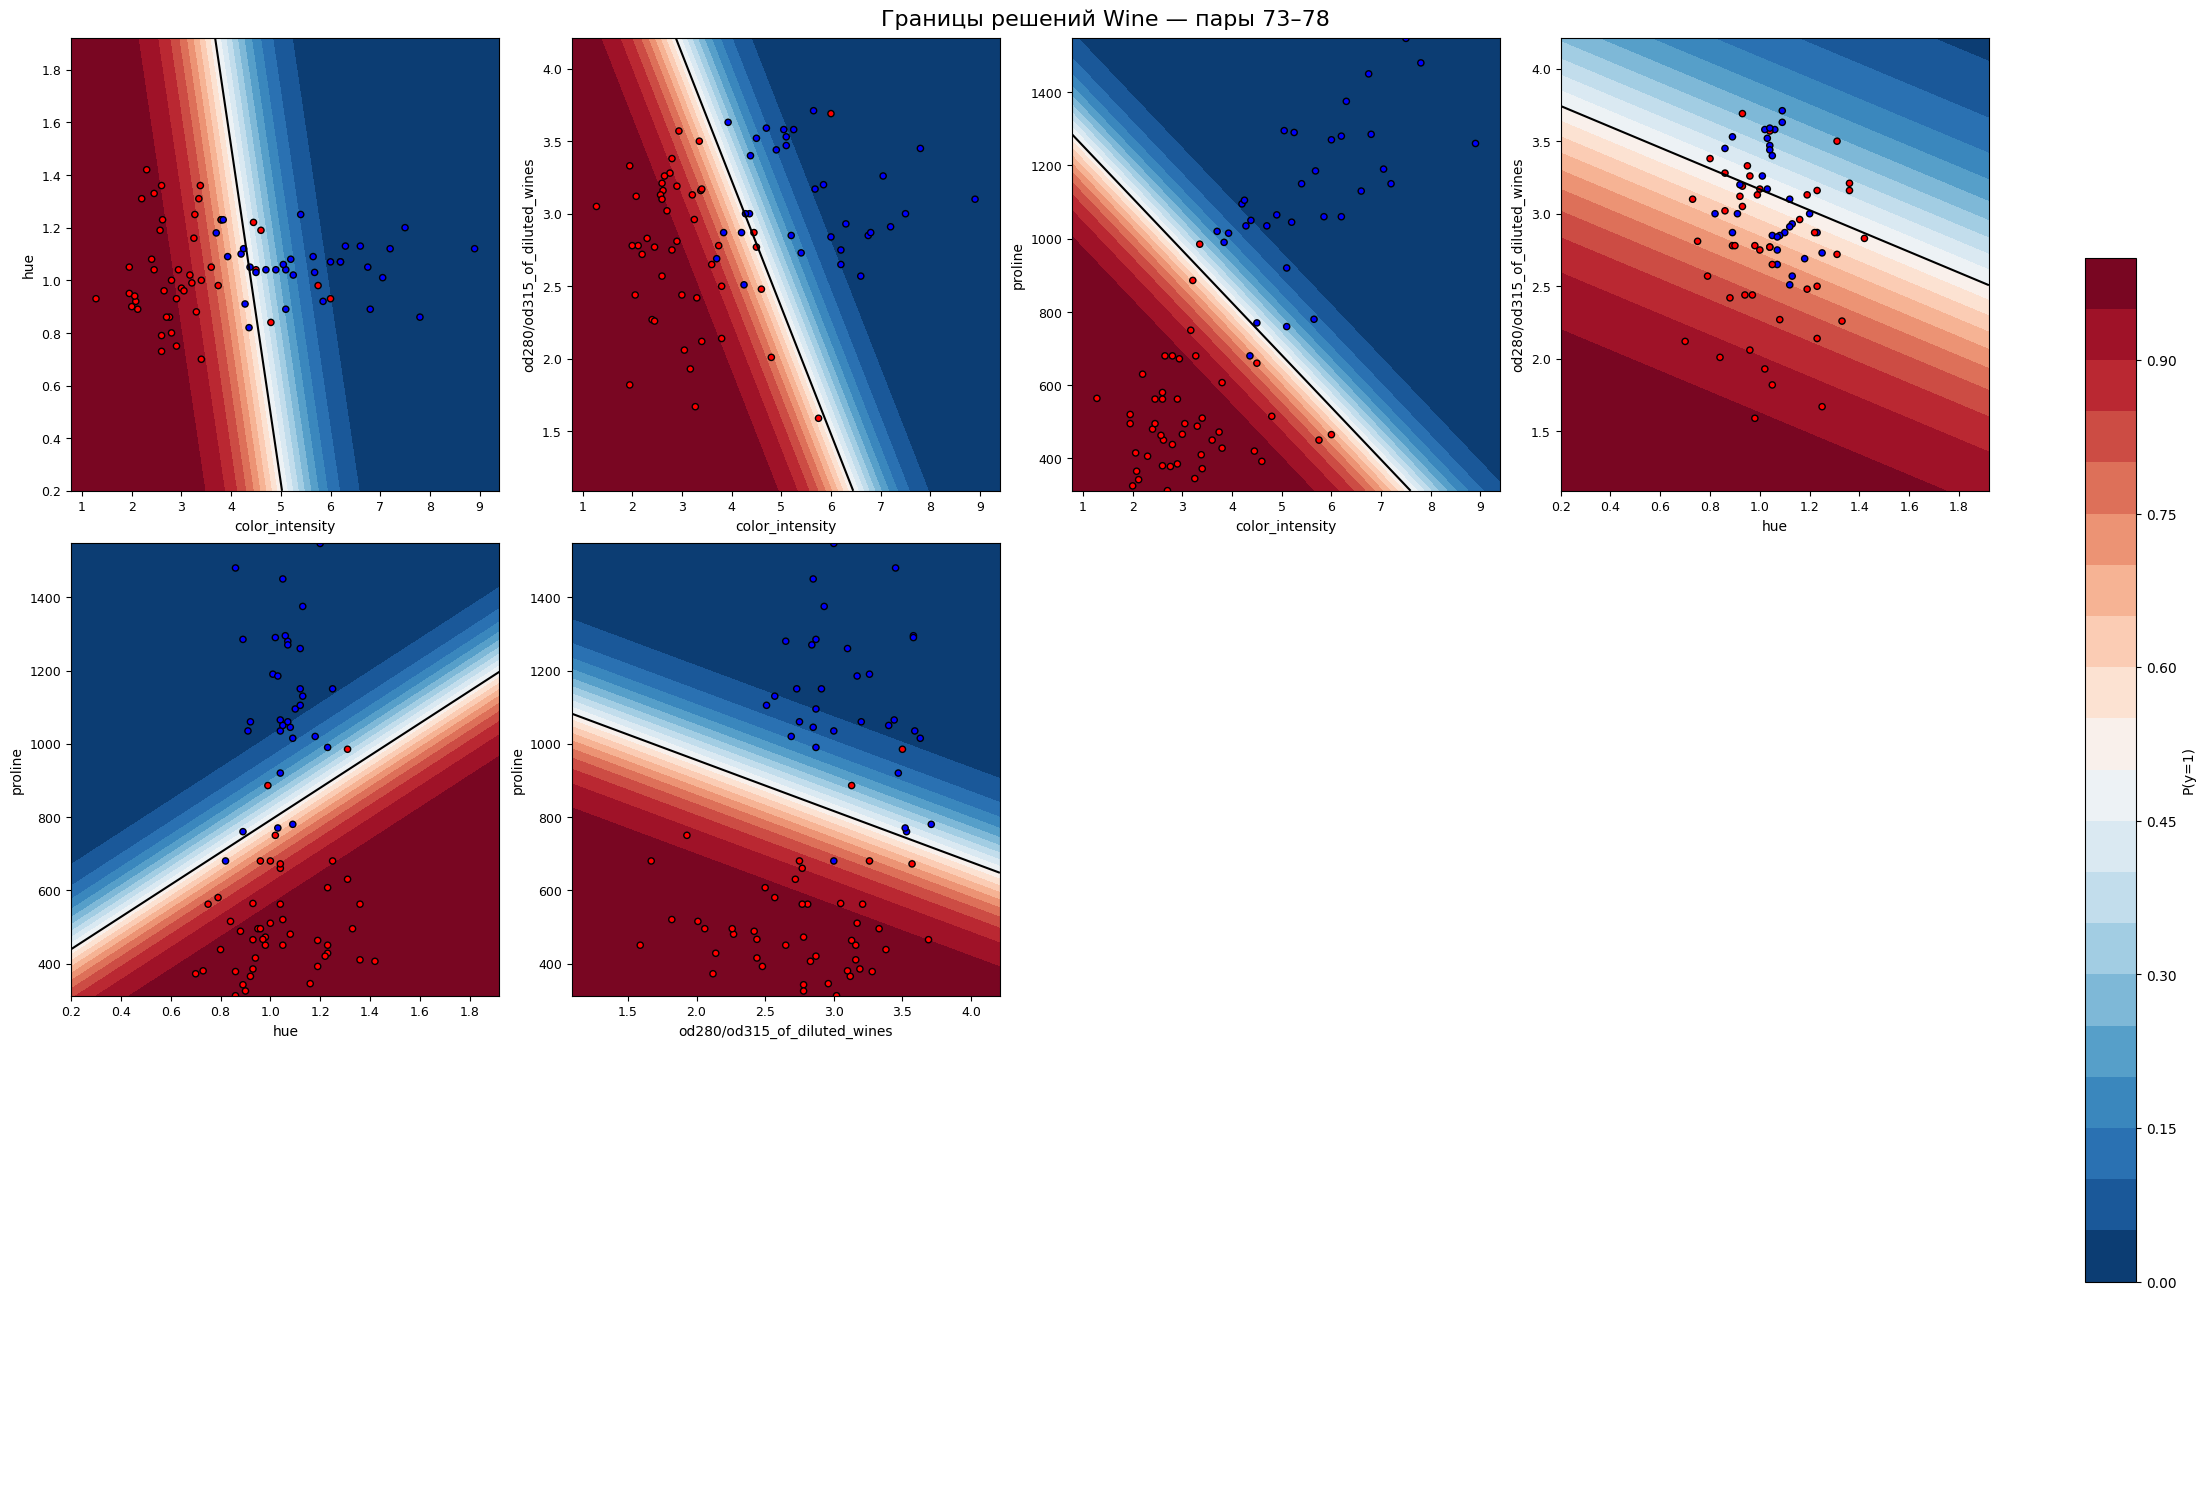

In [44]:
plot_logreg_boundaries_all_pairs(X_train_raw, y_train, feature_names, LogisticRegression)

**Вопросы.** Назови две пары, для которых прямая хорошо разделяет классы на train, и две пары с заметным перекрытием. Может ли нелинейная граница помочь при перекрытии? Как проверить эту гипотезу на новых объектах?

На train хорошо разделяются классы для пар alcohol — proline и alcohol — flavanoids: большинство объектов разных классов находится по разные стороны прямой.
Заметное перекрытие наблюдается для пар malic_acid — ash и malic_acid — hue: объекты разных классов перемешаны, поэтому линейная граница допускает много ошибок.
Нелинейная граница может помочь, если данные имеют нелинейную структуру. Однако при сильном перекрытии врядли.

## Target transformation

Сравним линейную регрессию и дерево при четырёх преобразованиях таргета. Все метрики качества будем считать после обратного преобразования в исходных денежных единицах.

### Задание 3 [0,5 балла]

Загрузи Ames Housing (`house_prices`, версия 1), выдели `SalePrice` и исключи служебный `Id`. Сначала раздели данные на train/test с `test_size=0.2, random_state=42`. Создай `ColumnTransformer`: для числовых признаков импутация средним и StandardScaler, для категориальных импутация модой и OneHotEncoder. Здесь создай препроцессор, но не вызывай `fit_transform` до CV.

In [45]:
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer, PowerTransformer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold

ames = fetch_openml(name="house_prices", version=1, as_frame=True)
df = ames.frame
y = df['SalePrice'].to_numpy(dtype=float)
X = df.drop(columns=['SalePrice', 'Id'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Определи categorical_features и numeric_features по X_train.
# Создай preprocessor. Он будет обучаться внутри Pipeline на каждом CV-фолде.
# Напиши код здесь

categorical_features = X_train.select_dtypes(include=['object', 'category']).columns
numeric_features = X_train.select_dtypes(include=['number']).columns

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))     
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

### Задание 4 [1,5 балла]

### Задание 4.1 [0,2 балла]

Заполни тело функции `apply_transformations()`. В функции уже реализована базовая версия: «Оригинал» — без преобразования и `log1p(y)` — лог-преобразование. Необходимо добавить ещё два преобразования:
- квадратный корень для неотрицательных цен. При обратном преобразовании отрицательный прогноз в шкале корня ограничь нулём, затем возведи в квадрат.

- Yeo — Johnson, более универсальное преобразование, похожее на Box — Cox, но умеет работать с отрицательными значениями и нулями, для его реализации используй `sklearn.preprocessing.PowerTransformer(method="yeo-johnson")`.

Функция должна возвращать словарь transforms:
- где ключ — название преобразования (строка);
- значение — кортеж из трёх элементов:
   - `y_transformed` — преобразованный `y_train`;
   - `inverse_transform_func` — функция, выполняющая обратное преобразование;
   - `transform_func` — функция, применяющая преобразование (она позволяет проверить прямое и обратное преобразования).

In [46]:
from scipy.stats import boxcox
from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score, GridSearchCV


def apply_transformations(y_train):
    y_train = np.asarray(y_train)
    transforms = {
        "Оригинал": (y_train, lambda x: x, lambda x: x),
        "log1p(y)": (np.log1p(y_train), np.expm1, np.log1p)
    }
    # Напиши код здесь
    transforms["sqrt(y)"] = (
        np.sqrt(y_train),
        lambda x: np.maximum(x, 0) ** 2,
        np.sqrt
    )
    
    pt = PowerTransformer(method="yeo-johnson")
    y_transformed = pt.fit_transform(y_train.reshape(-1, 1)).ravel()
    
    transforms["Yeo-Johnson"] = (
        y_transformed,
        lambda x: pt.inverse_transform(np.asarray(x).reshape(-1, 1)).ravel(),
        lambda x: pt.transform(np.asarray(x).reshape(-1, 1)).ravel()
    )
    
    return transforms

### Задание 4.2 [1 балл]

Реализуй `evaluate_model_cv(transform_name, config, X_train, y_train, X_test, y_test)`.

1. Создай преобразователь таргета: `FunctionTransformer` для тождественного преобразования, log1p/expm1 и sqrt/квадрата, `PowerTransformer(method="yeo-johnson")` для Yeo–Johnson.
2. Собери `Pipeline([("preprocess", clone(preprocessor)), ("model", clone(config["estimator"]))])`.
3. Оберни pipeline в `TransformedTargetRegressor(regressor=..., transformer=...)`. Он обучает преобразование y внутри каждого фолда и возвращает прогноз в исходной шкале. Пример имени параметра для GridSearchCV: `regressor__model__max_depth`.
4. Используй одинаковый `KFold(n_splits=5, shuffle=True, random_state=42)` и `scoring="neg_mean_absolute_error"` для всех вариантов. Обучи GridSearchCV на исходном y_train. Препроцессинг X и преобразование y должны обучаться внутри CV.
5. Верни лучшие параметры, среднюю CV MAE, test MAE и test R². Test используется для сравнения заранее заданных вариантов, после просмотра результатов их не перенастраиваем.

`apply_transformations` из предыдущей подзадачи пригодится для рисунка распределений. Функцию, уже обученную на всём y_train, нельзя использовать как готовое преобразование внутри CV.

In [47]:
def evaluate_model_cv(transform_name, config, X_train, y_train, X_test, y_test):
    # Напиши код здесь
    
    if transform_name == "Оригинал":
        transformer = FunctionTransformer(
            func=lambda x: x,
            inverse_func=lambda x: x
        )

    elif transform_name == "log1p(y)":
        transformer = FunctionTransformer(
            func=np.log1p,
            inverse_func=np.expm1
        )

    elif transform_name == "sqrt(y)":
        transformer = FunctionTransformer(
            func=np.sqrt,
            inverse_func=lambda x: np.maximum(x, 0) ** 2,
            check_inverse=False
        )

    elif transform_name == "Yeo-Johnson":
        transformer = PowerTransformer(method="yeo-johnson")

    else:
        raise ValueError(f"Неизвестное преобразование: {transform_name}")

    pipeline = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", clone(config["estimator"]))
    ])

    regressor = TransformedTargetRegressor(
        regressor=pipeline,
        transformer=transformer
    )

    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    grid = GridSearchCV(
        estimator=regressor,
        param_grid=config["param_grid"],
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    y_pred = grid.predict(X_test)

    return {
        "best_params": grid.best_params_,
        "cv_mae": -grid.best_score_,
        "test_mae": mean_absolute_error(y_test, y_pred),
        "test_r2": r2_score(y_test, y_pred)
    }

Сравни `LinearRegression` с пустой сеткой параметров и `DecisionTreeRegressor` с сеткой `max_depth=[3, 5, 10]`, `min_samples_split=[2, 5, 10]`. Для обеих моделей используй четыре преобразования: `Оригинал`, `log1p(y)`, `sqrt(y)`, `Yeo–Johnson`. Вызови `evaluate_model_cv` для каждой комбинации и выведи результаты в таблице. Все варианты оцениваются на одних объектах и в исходной шкале SalePrice.

In [48]:
# Напиши код здесь
configs = {
    "LinearRegression": {
        "estimator": LinearRegression(),
        "param_grid": {}
    },
    "DecisionTreeRegressor": {
        "estimator": DecisionTreeRegressor(random_state=42),
        "param_grid": {
            "regressor__model__max_depth": [3, 5, 10],
            "regressor__model__min_samples_split": [2, 5, 10]
        }
    }
}

transformations = [
    "Оригинал",
    "log1p(y)",
    "sqrt(y)",
    "Yeo-Johnson"
]

results = []

for model_name, config in configs.items():
    for transform_name in transformations:
        result = evaluate_model_cv(
            transform_name,
            config,
            X_train,
            y_train,
            X_test,
            y_test
        )

        results.append({
            "Модель": model_name,
            "Преобразование": transform_name,
            "CV MAE": result["cv_mae"],
            "Test MAE": result["test_mae"],
            "Test R²": result["test_r2"],
            "Лучшие параметры": result["best_params"]
        })

results_df = pd.DataFrame(results)
display(results_df.round(2))

,Модель,Преобразование,CV MAE,Test MAE,Test R²,Лучшие параметры
0,LinearRegression,Оригинал,19730.58,18356.97,0.89,{}
1,LinearRegression,log1p(y),18395.69,14849.79,0.93,{}
2,LinearRegression,sqrt(y),17328.31,15509.95,0.92,{}
3,LinearRegression,Yeo-Johnson,19653.81,15130.33,0.93,{}
4,DecisionTreeRegressor,Оригинал,25202.82,26724.26,0.79,"{'regressor__model__max_depth': 10, 'regressor..."
5,DecisionTreeRegressor,log1p(y),26165.81,25796.04,0.76,"{'regressor__model__max_depth': 10, 'regressor..."
6,DecisionTreeRegressor,sqrt(y),26641.78,25629.91,0.82,"{'regressor__model__max_depth': 10, 'regressor..."
7,DecisionTreeRegressor,Yeo-Johnson,27227.81,23845.06,0.79,"{'regressor__model__max_depth': 10, 'regressor..."


### Задание 4.3 [0,3 балла]

Напиши о применении метода Target transformation на основе выведенных метрик:
- какие трансформации дали улучшение,
- для какой модели это было заметнее,
- почему так произошло?


Преобразования целевой переменной оказались наиболее полезными для линейной регрессии. 
Все три преобразования улучшили качество модели. 

Лучший результат на тестовой выборке показало log1p(y) (MAE снизилась с 18 357 до 14 850, а R² вырос с 0.89 до 0.93).
При этом на кросс-валидации лучший результат получен с sqrt(y) — MAE составила 17 328.

Для дерева решений эффект оказался менее выраженным. 
На кросс-валидации качество, наоборот, ухудшилось. 
Поэтому нельзя уверенно утверждать, что преобразования действительно улучшили обобщающую способность дерева.

Вероятно, это связано с тем, что цены на недвижимость имеют асимметричное распределение с дорогими объектами.


### Задание 5 [0,5 балла]

Построй распределения четырёх преобразований y_train на одном рисунке. Для сравнения формы вычти среднее и раздели на стандартное отклонение каждого преобразованного массива. Подпиши оси и легенду.

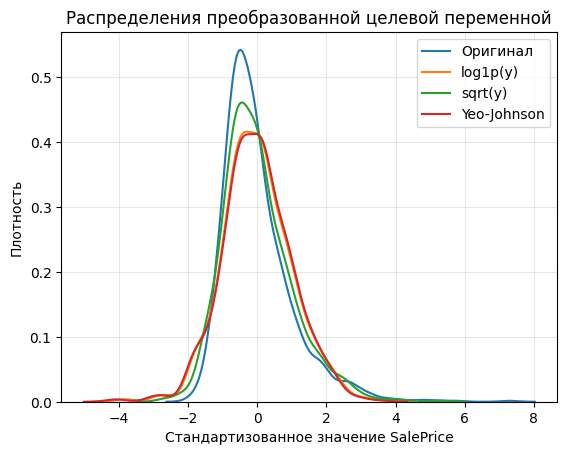

In [49]:
# Напиши код здесь
import seaborn as sns

transforms = apply_transformations(y_train)

plt.figure()

for name, (y_transformed, _, _) in transforms.items():
    y_scaled = (y_transformed - np.mean(y_transformed)) / np.std(y_transformed)

    sns.kdeplot(y_scaled, label=name)

plt.xlabel("Стандартизованное значение SalePrice")
plt.ylabel("Плотность")
plt.title("Распределения преобразованной целевой переменной")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Калибровка на реальных данных

Для хорошо откалиброванной модели среди объектов с вероятностью около 0,8 доля положительных меток близка к 80%. Проверим это по калибровочным кривым, Brier Score и Log Loss. Последние две метрики отражают также способность модели различать объекты, поэтому одного их значения недостаточно для диагноза калибровки.

### Задание 6 [2 балла]

Выбери три датасета бинарной классификации. Можно взять Breast Cancer, два класса Wine и два класса Digits из sklearn.

Для каждого датасета выдели train/test со стратификацией. Обучи библиотечную `LogisticRegression` (импортируй как `SklearnLogReg`, чтобы сохранить свой класс) и `SVC(probability=True)`. Масштабирование выполняй внутри Pipeline.

Для каждой модели сравни исходные вероятности с результатами `CalibratedClassifierCV` при `method='sigmoid'` и `method='isotonic'`. Передавай внутрь калибратора весь pipeline, чтобы scaler обучался заново внутри фолдов. Используй одну test для всех вариантов. Посчитай Brier Score и Log Loss и опиши, где метрики улучшились или ухудшились.

`SVC(probability=True)` уже использует внутреннюю сигмоидную калибровку. Его исходный вариант означает «без дополнительной внешней калибровки». При внешней калибровке можно использовать `SVC(probability=False)`, поскольку CalibratedClassifierCV работает с decision_function. Не делай вывод о причине изменения только по названию датасета.

In [50]:
# Обучи модели, сравни способы калибровки и выведи таблицу метрик.
# Напиши код здесь

from sklearn.datasets import load_breast_cancer, load_wine, load_digits
from sklearn.linear_model import LogisticRegression as SklearnLogReg
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.base import clone

# Загружаем датасеты
datasets = {
    "Breast Cancer": load_breast_cancer(),
    "Wine": load_wine(),
    "Digits": load_digits()
}

models = {
    "LogisticRegression": SklearnLogReg(max_iter=2000),
    "SVC": SVC(probability=True, random_state=42)
}

results = []

for dataset_name, data in datasets.items():
    X, y = data.data, data.target
    if dataset_name in ["Wine", "Digits"]:
        mask = y < 2
        X, y = X[mask], y[mask]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    for model_name, model in models.items():
        for method in ["original", "sigmoid", "isotonic"]:

            if method == "original":
                model = make_pipeline(
                    StandardScaler(),
                    clone(model)
                )
            else:
                # Внешняя калибровка SVC работает с decision_function
                if model_name == "SVC":
                    base_model = SVC(probability=False, random_state=42)
                else:
                    base_model = clone(model)

                pipeline = make_pipeline(
                    StandardScaler(),
                    base_model
                )

                model = CalibratedClassifierCV(
                    estimator=pipeline,
                    method=method,
                    cv=5
                )

            model.fit(X_train, y_train)

            probabilities = model.predict_proba(X_test)[:, 1]

            results.append({
                "Датасет": dataset_name,
                "Модель": model_name,
                "Калибровка": method,
                "Brier Score": brier_score_loss(y_test, probabilities),
                "Log Loss": log_loss(y_test, probabilities)
            })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Датасет,Модель,Калибровка,Brier Score,Log Loss
0,Breast Cancer,LogisticRegression,original,0.0215,0.0777
1,Breast Cancer,LogisticRegression,sigmoid,0.0271,0.1134
2,Breast Cancer,LogisticRegression,isotonic,0.0198,0.0654
3,Breast Cancer,SVC,original,0.0238,0.0860
4,Breast Cancer,SVC,sigmoid,0.0264,0.1063
5,Breast Cancer,SVC,isotonic,0.0244,0.0815
6,Wine,LogisticRegression,original,0.0300,0.1003
7,Wine,LogisticRegression,sigmoid,0.0386,0.1667
8,Wine,LogisticRegression,isotonic,0.0371,0.1064
9,Wine,SVC,original,0.0036,0.0325


## Калибровка методом Platt scaling

В заданиях со звёздочкой реализуй калибровку Платта и сравни её с простым преобразованием оценки SVM в диапазон [0, 1]. Оценивание этих заданий входит в общий максимум 10 баллов.

### Задание 7* [1 балл]

Реализуй калибровку Платта для бинарных меток 0/1 или −1/+1. Используй

$$p_i=\frac{1}{1+\exp(Af_i+B)},\qquad L=-\sum_i[t_i\log p_i+(1-t_i)\log(1-p_i)].$$

Здесь $f_i$ является оценкой базовой модели на объектах, которые не участвовали в её обучении. Сглаженные цели равны $(N_++1)/(N_++2)$ для положительных меток и $1/(N_-+2)$ для отрицательных. $N_+$ и $N_-$ являются числом положительных и отрицательных меток калибровочной выборки.

Минимизируй отрицательное логарифмическое правдоподобие по A и B. Для устойчивости используй `np.logaddexp`, проверь успешность оптимизации. Подробности: [Platt scaling и численная реализация](https://www.csie.ntu.edu.tw/~cjlin/papers/plattprob.pdf).

In [51]:
from scipy.optimize import minimize
from scipy.special import expit
import numpy as np

class PlattCalibration:
    def __init__(self):
        self.A = None
        self.B = None

    def _calc_t(self, y_array):
        y_array = np.asarray(y_array)

        n_pos = np.sum(y_array == 1)
        n_neg = np.sum(y_array != 1)

        t_pos = (n_pos + 1) / (n_pos + 2)
        t_neg = 1 / (n_neg + 2)

        t_array = np.where(y_array == 1, t_pos, t_neg)
        return t_array

    def _sigmoid(self, f, A, B):
        p_array = expit(-(A * f + B))
        return p_array

    def _neg_log_likelihood(self, params, f, y_array):
        A, B = params

        t = self._calc_t(y_array)
        z = A * f + B

        loss = np.sum(np.logaddexp(0, -z) + t * z)
        return loss

    def fit(self, f, y_array):
        f = np.asarray(f).ravel()
        y_array = np.asarray(y_array).ravel()

        n_pos = np.sum(y_array == 1)
        n_neg = np.sum(y_array != 1)

        if n_pos == 0 or n_neg == 0:
            raise ValueError("Для калибровки нужны оба класса")

        initial_params = [
            0.0,
            np.log((n_neg + 1) / (n_pos + 1))
        ]

        result = minimize(
            self._neg_log_likelihood,
            x0=initial_params,
            args=(f, y_array),
            method="BFGS"
        )

        if not result.success:
            raise RuntimeError(f"Оптимизация не сошлась: {result.message}")

        self.A, self.B = result.x
        return self

    def predict_proba(self, f):
        if self.A is None or self.B is None:
            raise ValueError("Сначала необходимо обучить модель через fit()")

        f = np.asarray(f)
        probs = self._sigmoid(f, self.A, self.B)

        return probs

Проверь реализацию Platt scaling на assert-тесте.

In [52]:
import numpy as np

model = PlattCalibration()

# Проверка _calc_t
t_pm1 = model._calc_t(np.array([-1, 1, -1]))
assert np.allclose(t_pm1, np.array([1/4, 2/3, 1/4])), "Ошибка: _calc_t неправильно сглаживает целевые метки"
print("Модуль _calc_t работает корректно")

# Проверка _sigmoid
p = model._sigmoid(np.array([-2.0, 0.0, 2.0]), A=1, B=0)
expected = 1 / (1 + np.exp(np.array([-2.0, 0.0, 2.0])))
assert np.allclose(p, expected), "Ошибка: сигмоида рассчитывается некорректно"
print("Модуль _sigmoid работает корректно")

# Проверка _neg_log_likelihood
loss = model._neg_log_likelihood([1, 0], np.array([-2.0, 0.0, 2.0]), np.array([-1, 1, -1]))
assert isinstance(loss, float), "Ошибка: _neg_log_likelihood должна возвращать число"
assert loss > 0, "Ошибка: значение функции потерь должно быть положительным"
print("Модуль _neg_log_likelihood работает корректно")

# Проверка fit
model.fit(np.array([-2.0, 0.0, 2.0]), np.array([-1, 1, -1]))
assert model.A is not None, "Ошибка: параметр A не определён после обучения"
assert model.B is not None, "Ошибка: параметр B не определён после обучения"
print("Модуль fit работает корректно")

# Проверка predict_proba
f_test = np.array([-1.5, 0.5, 1.5])
probs = model.predict_proba(f_test)
assert probs.shape == f_test.shape, "Ошибка: форма выходов predict_proba должна совпадать с входами"
assert np.all((probs >= 0) & (probs <= 1)), "Ошибка: вероятности должны быть в диапазоне [0, 1]"
print("Модуль predict_proba работает корректно")

print("Все тесты пройдены")

Модуль _calc_t работает корректно
Модуль _sigmoid работает корректно
Модуль _neg_log_likelihood работает корректно
Модуль fit работает корректно
Модуль predict_proba работает корректно
Все тесты пройдены


### Задание 8* [1 балл]

Обучи SVM на каждом обучающем фолде, а свой PlattCalibration на оценках соответствующего валидационного фолда. На общей test усредни прогнозы этих пар SVM и калибратор. Это ансамбль моделей, построенных на CV-фолдах.

Для сравнения усредни `expit(decision_function)` тех же SVM. Это условная вероятностная шкала без подбора A и B, а не вероятности, которые выдаёт сам SVM. Нельзя заменять её жёсткими метками классов и называть «вероятностями SVM».

Добавь библиотечную логистическую регрессию, обученную на всём train. Для трёх вариантов рассчитай Brier Score и Log Loss и построй калибровочные кривые. Масштабирование SVM обучай отдельно внутри каждого фолда.

In [53]:
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import LabelEncoder
from scipy.special import expit

data = fetch_openml(data_id=4534, as_frame=True)
X = data.data.to_numpy(dtype=float)
y = LabelEncoder().fit_transform(data.target.astype(str))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)

Для отрисовки графиков можешь дописать функцию или создать свою.

In [54]:
from sklearn.calibration import calibration_curve

def mult_plot_calibration_curve(y_test, preds_list, labels):
    # Для каждой серии раздели [0, 1] на 10 интервалов.
    # Последний интервал включает 1. Пустые интервалы пропускай.
    # По X откладывай среднюю вероятность внутри интервала,
    # по Y долю положительных меток, затем добавь диагональ.
    # Можно использовать sklearn.calibration.calibration_curve.
    plt.figure(figsize=(9, 6))

    for preds, label in zip(preds_list, labels):
        prob_true, prob_pred = calibration_curve(
            y_test,
            preds,
            n_bins=10,
            strategy="uniform"
        )

        plt.plot(
            prob_pred,
            prob_true,
            marker="o",
            label=label
        )

    plt.plot([0, 1], [0, 1], "k--", label="Идеальная калибровка")

    plt.xlabel("Средняя предсказанная вероятность")
    plt.ylabel("Доля положительных объектов")
    plt.title("Калибровочные кривые")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

In [55]:
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression as SklearnLogReg
from scipy.special import expit
from sklearn.metrics import brier_score_loss, log_loss

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

platt_preds = []
svm_preds = []

for train_idx, val_idx in cv.split(X_train, y_train):
    X_fold_train = X_train[train_idx]
    X_fold_val = X_train[val_idx]

    y_fold_train = y_train[train_idx]
    y_fold_val = y_train[val_idx]

    # Обучаем SVM вместе со scaler
    svm = make_pipeline(
        StandardScaler(),
        SVC(probability=False, random_state=42)
    )

    svm.fit(X_fold_train, y_fold_train)

    # Оценки на валидационном фолде
    f_val = svm.decision_function(X_fold_val)

    # Обучаем свою калибровку Платта
    platt = PlattCalibration()
    platt.fit(f_val, y_fold_val)

    # Оценки той же SVM на общей test
    f_test = svm.decision_function(X_test)

    # Откалиброванные вероятности
    platt_preds.append(platt.predict_proba(f_test))

    # Вероятности на условной шкале без калибровки
    svm_preds.append(expit(f_test))


# Усредняем предсказания пяти моделей
p_platt = np.mean(platt_preds, axis=0)
p_svm = np.mean(svm_preds, axis=0)

# Логистическая регрессия на всём train
logreg = make_pipeline(
    StandardScaler(),
    SklearnLogReg(max_iter=2000, random_state=42)
)

logreg.fit(X_train, y_train)

p_logreg = logreg.predict_proba(X_test)[:, 1]

In [56]:
preds_list = [p_platt, p_svm, p_logreg]

labels = [
    "SVM + Platt",
    "SVM + expit",
    "LogisticRegression"
]

results = []

for label, preds in zip(labels, preds_list):
    results.append({
        "Модель": label,
        "Brier Score": brier_score_loss(y_test, preds),
        "Log Loss": log_loss(y_test, preds)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Модель,Brier Score,Log Loss
0,SVM + Platt,0.0391,0.1386
1,SVM + expit,0.0640,0.2577
2,LogisticRegression,0.0552,0.1833


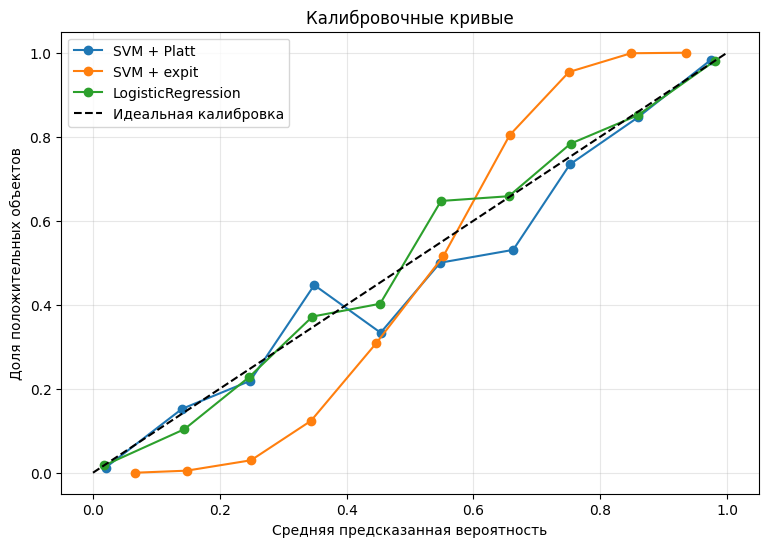

In [57]:
mult_plot_calibration_curve(y_test, preds_list, labels)

**Вопрос.** Сравни вероятностные метрики и кривые для среднего sigmoid(score), среднего прогноза после Platt и логистической регрессии. Где калибровка улучшила результат, а где ухудшила? Какой вывод можно сделать на этой test?

Калибровка Платта улучшила обе вероятностные метрики SVM: Brier Score снизился с 0,0640 до 0,0391, а Log Loss — с 0,2577 до 0,1386. SVM после калибровки также превзошёл логистическую регрессию, у которой Brier Score составил 0,0552, а Log Loss — 0,1833.
После калибровки Платта кривая в целом приблизилась к диагонали, хотя локальные отклонения сохранились. 
Например, около вероятности 0,45 отклонение стало немного больше. Кривая логистической регрессии тоже проходит близко к диагонали.
На данной test SVM с калибровкой Платта показал лучший результат по обеим метрикам. В целом калибровка улучшила качество вероятностных прогнозов SVM, хотя улучшение наблюдается не во всех интервалах вероятностей.

Теперь ты знаешь:
- как реализовывать собственную векторизованную логистическую регрессию, обучать её на реальных данных и визуализировать разделяющие границы;
- исследовать, как различные преобразования целевой переменной влияют на качество линейных и древовидных моделей регрессии, и делать выводы о целесообразности этих трансформаций;
- проверять, как калибровка вероятностей (Platt scaling и изотоническая регрессия) влияют на метрики качества прогнозов для разных моделей и датасетов;
- реализовывать метод Platt scaling с нуля и сравнивать качество вероятностных прогнозов моделей до и после калибровки, визуализировать калибровочные кривые и анализировать, где калибровка наиболее полезна.